# FloorRefine on GenEval50

FloorRefine combines white-floor initialisation with quality-guided refinement during denoising. In this experiment, we ask whether a modest optimisation budget can improve image quality while retaining the diversity associated with the starting noise. We also apply the same refinement procedure to white and pink noise to examine how the choice of initialisation affects this balance.

We use SDXL-Turbo with four denoising steps at 512 × 512 resolution. For each of 50 GenEval prompts, we generate a group of four images from each initialisation, then update the initial noise for ten iterations using HPSv2 as the quality reward. The generator and reward-model weights remain fixed. We save both the baseline and selected optimised images, giving 1,200 images in total, and evaluate quality, text alignment, and diversity separately.

### Running the experiment

Use the **generation kernel for Sections 1–6** and the **metrics kernel for Sections 7–13**. If images have already been generated, start at Section 7: it checks the selected run and allows evaluation only when the required results are complete. Otherwise, return to Sections 1–6 to generate or resume the run.

The metrics kernel launches each evaluator in turn. Core metrics use `.venv-metrics`, while MANIQA uses `.venv-maniqa`; no manual kernel switch is needed for MANIQA. Shut down unused generation kernels before evaluation so that their models do not occupy memory.

Place the notebook in `denoising_optimization/`. Results are saved under `denoising_optimization/outputs/initial_noise_optimize_geneval50/<run_name>/`. Keep the shared `noise_init/` and `pc_specific_psd/` modules at the project root.


## 1. Prepare the generation environment

The generation environment needs the project dependencies and HPSv2. The following cells prepare HPSv2 and import the libraries used for sampling and optimisation. Configure model-cache access and any required Hugging Face authentication in the environment before running them.


In [ ]:
# Uncomment only to install missing dependencies; restart the kernel if required.
# %pip install "diffusers==0.37.1" accelerate safetensors transformers pillow numpy pandas matplotlib
# Install HPSv2 in the generation environment when QUALITY_WEIGHT > 0:
# %pip install hpsv2


In [ ]:
from importlib.metadata import distribution
from pathlib import Path

path = Path(distribution("hpsv2").locate_file(
    "hpsv2/src/open_clip/factory.py"
))
source = path.read_text(encoding="utf-8")
bad_line = "from turtle import forward"

if bad_line in source:
    backup = path.with_suffix(".py.bak")
    if not backup.exists():
        backup.write_text(source, encoding="utf-8")
    source = "\n".join(
        line for line in source.split("\n")
        if line.strip() != bad_line
    )
    path.write_text(source, encoding="utf-8")
    print("Removed the unused turtle import from HPSv2.")
else:
    print("The turtle import is absent; inspect the full traceback if an error persists.")

In [ ]:
from importlib.metadata import distribution
from pathlib import Path
import urllib.request
import hashlib

target = Path(distribution("hpsv2").locate_file(
    "hpsv2/src/open_clip/bpe_simple_vocab_16e6.txt.gz"
))

url = (
    "https://raw.githubusercontent.com/openai/CLIP/main/"
    "clip/bpe_simple_vocab_16e6.txt.gz"
)
expected_sha = "924691ac288e54409236115652ad4aa250f48203de50a9e4722a6ecd48d6804a"

if not target.exists():
    with urllib.request.urlopen(url, timeout=60) as response:
        data = response.read()
    assert hashlib.sha256(data).hexdigest() == expected_sha, "File checksum verification failed."
    target.write_bytes(data)

assert hashlib.sha256(target.read_bytes()).hexdigest() == expected_sha
print("HPSv2 vocabulary ready:", target)

In [ ]:
import gc, hashlib, importlib.metadata, json, math, os, time
from pathlib import Path
from itertools import combinations
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from IPython.display import display

torch.set_num_threads(min(8, os.cpu_count() or 1))
print('torch:', torch.__version__, 'CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))


## 2. Choose the prompts and experimental settings

We use a fixed subset of 50 prompts from the 400-prompt [GenEval](https://github.com/djghosh13/geneval) pool used in the initialisation experiments. The subset covers all six categories, with the number of prompts in each category chosen in proportion to its share of the pool. We allocate the integer counts by the largest-remainder method and select prompts within each category using a seeded hash ranking (`selection_seed = 20261023`). The fixed prompt list and sampling metadata are stored in the collapsed cell below the configuration. Run that cell as part of setup; it does not need to be expanded.

| Category | Number of prompts |
| --- | ---: |
| Single object | 7 |
| Two objects | 9 |
| Counting | 7 |
| Colours | 9 |
| Spatial position | 9 |
| Colour attribute binding | 9 |
| **Total** | **50** |

Each prompt has one group of four seeds. We use the same base Gaussian samples and scheduler random draws across initialisations, so the comparisons are paired. The three starting points are white noise, pink noise with α = 0.3, and same-phase white-floor noise with α = 0.9 and γ = 0.05.

For the quality-only experiment, `DIVERSITY_ENABLED=False` and `QUALITY_WEIGHT=1.0`. We optimise an additive increment to the initial noise using Adam with a learning rate of 0.01 for ten updates. The increment is limited to 10% of the starting noise norm for each sample. HPSv3 is used only for evaluation, not to guide optimisation or select candidates. The diversity term remains available through `DIVERSITY_ENABLED` for a separate joint-objective experiment.

Keep `RUN_NAME` and the configuration unchanged when resuming a run. Use a different name when changing the experimental settings.


In [ ]:
MODEL_ID = 'stabilityai/sdxl-turbo'
VAE_ID = 'madebyollin/sdxl-vae-fp16-fix'
CACHE_DIR = '/workspace/Initial_Noise_Optimization/noise_init/cache'  # Model cache directory; set to None to use the default cache.
HEIGHT = WIDTH = 512
NUM_STEPS = 4
EDIT_AFTER_STEP = 0  # Update the initial noise before the first denoising step for all initialisations.
ALPHA, GAMMA = 0.9, 0.05
INIT_CONFIGS = {
    'white': {'method': 'white', 'alpha': 0.0, 'gamma': None},
    'pink03': {'method': 'pink', 'alpha': 0.3, 'gamma': None},
    'whitefloor': {'method': 'same_phase_whitefloor', 'alpha': ALPHA, 'gamma': GAMMA},
}

DEVICE = 'cuda'
MODEL_PRECISION = 'float16'  # float16 / bfloat16 / float32; restart the kernel after changing precision.
GRAD_CHECKPOINT = True      # Checkpoint each UNet call; do not use model offload hooks during backpropagation.
MAX_REL_EDIT = 0.10
OPT_STEPS = 10              # Number of updates; also evaluate the candidate after the final update.
OPT_RESTARTS = 1            # 3 means one zero-increment start and two small random starts.
OPT_LR = 0.01
OPT_SEED = 731
VJP_SCALE = 128.0           # Fixed fp16 gradient scale; divided out after backpropagation to preserve objective weights.
STRENGTHS = [0.0, 1.0]
SAVE_EVERY = 5
OUTPUT_ROOT = None         # Default: denoising_optimization/outputs/initial_noise_optimize_geneval50

DIVERSITY_ENABLED = False   # False: quality-only; True: joint quality and diversity objective.
QUALITY_WEIGHT = 1.0        # Quality weight; set to 0 to bypass HPSv2.
QUALITY_DEVICE = 'cuda'      # Device for differentiable VAE and HPS evaluation; shares GPU memory with the UNet.
HPS_CHECKPOINT = None       # None downloads the official HPSv2.0 weights; alternatively, supply a local checkpoint.

PROJECT_ROOT = None  # Search parent directories from cwd; alternatively, specify the project root.
NORMALIZATION_PROFILE = 'per_sample_per_channel_zero_mean_unit_std'

# Batch settings
RUN_NAME = "geneval50_quality10_v1"  # An empty name selects geneval50_joint10_v1 / geneval50_quality10_v1 automatically.
RESUME = True
SHOW_INLINE = False  # Images are saved in each prompt directory regardless of inline display.
BATCH_CODE_VERSION = "geneval50_v1"


In [ ]:
# Fixed GenEval prompts and sampling settings. Run this cell before generation.
PROMPT_SOURCE = {'selection_seed': 20261023, 'selection': 'proportional categories, largest remainder (ties ascending category), within category SHA256(seed|prompt_id|prompt); restore source order', 'category_counts': {'single_object': 7, 'two_object': 9, 'counting': 7, 'colors': 9, 'position': 9, 'color_attr': 9}}

GENEVAL50 = [
    {'prompt_id': 'geneval_0010', 'prompt': 'a photo of a microwave', 'category': 'single_object', 'batch_seed': 4100100, 'source_row': 11},
    {'prompt_id': 'geneval_0013', 'prompt': 'a photo of a zebra', 'category': 'single_object', 'batch_seed': 4100130, 'source_row': 14},
    {'prompt_id': 'geneval_0014', 'prompt': 'a photo of a parking meter', 'category': 'single_object', 'batch_seed': 4100140, 'source_row': 15},
    {'prompt_id': 'geneval_0047', 'prompt': 'a photo of an oven', 'category': 'single_object', 'batch_seed': 4100470, 'source_row': 48},
    {'prompt_id': 'geneval_0058', 'prompt': 'a photo of a fire hydrant', 'category': 'single_object', 'batch_seed': 4100580, 'source_row': 59},
    {'prompt_id': 'geneval_0059', 'prompt': 'a photo of an airplane', 'category': 'single_object', 'batch_seed': 4100590, 'source_row': 60},
    {'prompt_id': 'geneval_0071', 'prompt': 'a photo of a bus', 'category': 'single_object', 'batch_seed': 4100710, 'source_row': 72},
    {'prompt_id': 'geneval_0081', 'prompt': 'a photo of a toothbrush and a snowboard', 'category': 'two_object', 'batch_seed': 4100810, 'source_row': 82},
    {'prompt_id': 'geneval_0091', 'prompt': 'a photo of a hair drier and a bear', 'category': 'two_object', 'batch_seed': 4100910, 'source_row': 92},
    {'prompt_id': 'geneval_0102', 'prompt': 'a photo of a skateboard and a cake', 'category': 'two_object', 'batch_seed': 4101020, 'source_row': 103},
    {'prompt_id': 'geneval_0124', 'prompt': 'a photo of a scissors and a sandwich', 'category': 'two_object', 'batch_seed': 4101240, 'source_row': 125},
    {'prompt_id': 'geneval_0125', 'prompt': 'a photo of a pizza and a book', 'category': 'two_object', 'batch_seed': 4101250, 'source_row': 126},
    {'prompt_id': 'geneval_0136', 'prompt': 'a photo of a cow and a horse', 'category': 'two_object', 'batch_seed': 4101360, 'source_row': 137},
    {'prompt_id': 'geneval_0160', 'prompt': 'a photo of a tie and a broccoli', 'category': 'two_object', 'batch_seed': 4101600, 'source_row': 161},
    {'prompt_id': 'geneval_0172', 'prompt': 'a photo of a microwave and a bench', 'category': 'two_object', 'batch_seed': 4101720, 'source_row': 173},
    {'prompt_id': 'geneval_0178', 'prompt': 'a photo of a baseball bat and a giraffe', 'category': 'two_object', 'batch_seed': 4101780, 'source_row': 179},
    {'prompt_id': 'geneval_0185', 'prompt': 'a photo of two ties', 'category': 'counting', 'batch_seed': 4101850, 'source_row': 186},
    {'prompt_id': 'geneval_0201', 'prompt': 'a photo of three handbags', 'category': 'counting', 'batch_seed': 4102010, 'source_row': 202},
    {'prompt_id': 'geneval_0234', 'prompt': 'a photo of two sandwichs', 'category': 'counting', 'batch_seed': 4102340, 'source_row': 235},
    {'prompt_id': 'geneval_0244', 'prompt': 'a photo of two teddy bears', 'category': 'counting', 'batch_seed': 4102440, 'source_row': 245},
    {'prompt_id': 'geneval_0245', 'prompt': 'a photo of four skateboards', 'category': 'counting', 'batch_seed': 4102450, 'source_row': 246},
    {'prompt_id': 'geneval_0254', 'prompt': 'a photo of four benchs', 'category': 'counting', 'batch_seed': 4102540, 'source_row': 255},
    {'prompt_id': 'geneval_0256', 'prompt': 'a photo of four frisbees', 'category': 'counting', 'batch_seed': 4102560, 'source_row': 257},
    {'prompt_id': 'geneval_0273', 'prompt': 'a photo of a red zebra', 'category': 'colors', 'batch_seed': 4102730, 'source_row': 274},
    {'prompt_id': 'geneval_0298', 'prompt': 'a photo of a purple carrot', 'category': 'colors', 'batch_seed': 4102980, 'source_row': 299},
    {'prompt_id': 'geneval_0300', 'prompt': 'a photo of a purple potted plant', 'category': 'colors', 'batch_seed': 4103000, 'source_row': 301},
    {'prompt_id': 'geneval_0301', 'prompt': 'a photo of a purple backpack', 'category': 'colors', 'batch_seed': 4103010, 'source_row': 302},
    {'prompt_id': 'geneval_0309', 'prompt': 'a photo of a yellow parking meter', 'category': 'colors', 'batch_seed': 4103090, 'source_row': 310},
    {'prompt_id': 'geneval_0320', 'prompt': 'a photo of a green clock', 'category': 'colors', 'batch_seed': 4103200, 'source_row': 321},
    {'prompt_id': 'geneval_0326', 'prompt': 'a photo of a black hot dog', 'category': 'colors', 'batch_seed': 4103260, 'source_row': 327},
    {'prompt_id': 'geneval_0337', 'prompt': 'a photo of a blue carrot', 'category': 'colors', 'batch_seed': 4103370, 'source_row': 338},
    {'prompt_id': 'geneval_0349', 'prompt': 'a photo of a blue book', 'category': 'colors', 'batch_seed': 4103490, 'source_row': 350},
    {'prompt_id': 'geneval_0368', 'prompt': 'a photo of a baseball glove below an umbrella', 'category': 'position', 'batch_seed': 4103680, 'source_row': 369},
    {'prompt_id': 'geneval_0377', 'prompt': 'a photo of a tv remote left of an umbrella', 'category': 'position', 'batch_seed': 4103770, 'source_row': 378},
    {'prompt_id': 'geneval_0385', 'prompt': 'a photo of a kite above a toothbrush', 'category': 'position', 'batch_seed': 4103850, 'source_row': 386},
    {'prompt_id': 'geneval_0389', 'prompt': 'a photo of a stop sign above a chair', 'category': 'position', 'batch_seed': 4103890, 'source_row': 390},
    {'prompt_id': 'geneval_0398', 'prompt': 'a photo of a toilet left of a kite', 'category': 'position', 'batch_seed': 4103980, 'source_row': 399},
    {'prompt_id': 'geneval_0408', 'prompt': 'a photo of a frisbee below a horse', 'category': 'position', 'batch_seed': 4104080, 'source_row': 409},
    {'prompt_id': 'geneval_0419', 'prompt': 'a photo of a hot dog above a knife', 'category': 'position', 'batch_seed': 4104190, 'source_row': 420},
    {'prompt_id': 'geneval_0421', 'prompt': 'a photo of a chair left of a zebra', 'category': 'position', 'batch_seed': 4104210, 'source_row': 422},
    {'prompt_id': 'geneval_0438', 'prompt': 'a photo of a horse right of a broccoli', 'category': 'position', 'batch_seed': 4104380, 'source_row': 439},
    {'prompt_id': 'geneval_0455', 'prompt': 'a photo of a green skis and a brown airplane', 'category': 'color_attr', 'batch_seed': 4104550, 'source_row': 456},
    {'prompt_id': 'geneval_0485', 'prompt': 'a photo of a pink tv remote and a blue airplane', 'category': 'color_attr', 'batch_seed': 4104850, 'source_row': 486},
    {'prompt_id': 'geneval_0491', 'prompt': 'a photo of a white pizza and a green umbrella', 'category': 'color_attr', 'batch_seed': 4104910, 'source_row': 492},
    {'prompt_id': 'geneval_0500', 'prompt': 'a photo of a yellow dining table and a pink dog', 'category': 'color_attr', 'batch_seed': 4105000, 'source_row': 501},
    {'prompt_id': 'geneval_0505', 'prompt': 'a photo of a red laptop and a brown car', 'category': 'color_attr', 'batch_seed': 4105050, 'source_row': 506},
    {'prompt_id': 'geneval_0509', 'prompt': 'a photo of a brown computer mouse and a purple bottle', 'category': 'color_attr', 'batch_seed': 4105090, 'source_row': 510},
    {'prompt_id': 'geneval_0542', 'prompt': 'a photo of a brown giraffe and a white stop sign', 'category': 'color_attr', 'batch_seed': 4105420, 'source_row': 543},
    {'prompt_id': 'geneval_0545', 'prompt': 'a photo of a red clock and a black cell phone', 'category': 'color_attr', 'batch_seed': 4105450, 'source_row': 546},
    {'prompt_id': 'geneval_0547', 'prompt': 'a photo of a red cup and a pink handbag', 'category': 'color_attr', 'batch_seed': 4105470, 'source_row': 548},
]


## 3. Refine the initial noise

We backpropagate the HPSv2 reward through decoding and denoising to the initial-noise increments, constrain their norms, and select the best candidate. Trajectories are recomputed one image at a time to limit memory use.


In [ ]:
PAIRS = list(combinations(range(4), 2))

def pair_mse(z):
    return torch.stack([(z[i] - z[j]).square().mean() for i, j in PAIRS])

def relative_edit(origin, delta):
    return delta.flatten(1).norm(dim=1) / origin.flatten(1).norm(dim=1).clamp_min(1e-12)

def project_edit(delta, origin, cap):
    # Budget is measured against the actual noisy state being edited, not a clean proxy.
    ratio = relative_edit(origin, delta)
    return delta * (cap / ratio.clamp_min(1e-12)).clamp(max=1).view(-1, 1, 1, 1)

def evaluate_final_objective(finals, diversity_scale, quality_fn=None,
                             quality_weight=0.0, diversity_weight=1.0):
    """J = diversity_weight * normalized minimum pair MSE + quality_weight * mean HPSv2.

    Return the exact joint gradient dJ/d(finals), using one quality graph at a time.
    The fifth return value is the unweighted mean quality, never a penalty.
    """
    if not math.isfinite(quality_weight) or quality_weight < 0 or diversity_scale <= 0:
        raise ValueError('Invalid quality weight or fixed diversity scale.')
    if not math.isfinite(diversity_weight) or diversity_weight < 0:
        raise ValueError('Invalid diversity weight.')
    if diversity_weight == 0 and quality_weight == 0:
        raise ValueError('At least one objective must be enabled.')
    z = finals.detach().float().cpu().requires_grad_(True)
    if z.shape[0] != 4:
        raise ValueError('This objective requires exactly four images.')
    distances = pair_mse(z)
    diversity = diversity_weight * distances.min() / diversity_scale
    grad = torch.autograd.grad(diversity, z)[0] if diversity_weight > 0 else torch.zeros_like(z)
    scores = []
    if quality_weight > 0:
        if quality_fn is None:
            raise ValueError('Positive QUALITY_WEIGHT requires differentiable HPSv2.')
        for i in range(4):
            leaf = finals[i:i+1].detach().float().cpu().requires_grad_(True)
            q = quality_fn(leaf).reshape(())
            quality_grad = torch.autograd.grad(quality_weight * q / 4, leaf)[0]
            grad[i:i+1] += quality_grad.detach().cpu()
            scores.append(float(q.detach().cpu()))
    quality_mean = sum(scores) / 4 if scores else None
    score = float(diversity.detach()) + (quality_weight * quality_mean if scores else 0.0)
    if not math.isfinite(score) or not torch.isfinite(grad).all():
        raise RuntimeError('Non-finite objective or final-latent gradient.')
    return score, grad, distances.detach(), scores, quality_mean

def solve_rollout(origin, baseline_finals, forward_one, *, steps, restarts, lr,
                  rel_cap, seed, vjp_scale=1.0, quality_fn=None,
                  quality_weight=0.0, diversity_weight=1.0, log_callback=None):
    """Optimize a shared four-image candidate using exact sequential chain-rule VJPs.

    forward_one(i, candidate_state, with_grad) always restarts the SAME suffix
    with the SAME random-number state. It must not detach when with_grad=True.
    Two passes avoid storing four UNet computation graphs simultaneously:
    (1) collect finals, derive joint dJ/d(finals); (2) recompute each suffix and VJP.
    """
    origin = origin.detach().float().cpu().clone()
    baseline_finals = baseline_finals.detach().float().cpu()
    assert origin.shape[0] == 4 and torch.isfinite(origin).all()
    assert steps >= 1 and restarts >= 1 and lr > 0 and rel_cap > 0
    rms = origin.square().mean((1, 2, 3), keepdim=True).sqrt().clamp_min(1e-8)
    diversity_scale = max(float(pair_mse(baseline_finals).mean()), 1e-8)
    settings = dict(quality_fn=quality_fn, quality_weight=quality_weight, diversity_weight=diversity_weight)
    baseline_score, _, _, baseline_quality, _ = evaluate_final_objective(
        baseline_finals, diversity_scale, **settings)
    best_score = baseline_score
    best_delta = torch.zeros_like(origin)
    best_finals = baseline_finals.clone()
    best_location = {'restart': -1, 'iteration': 0}
    rng = torch.Generator(device='cpu').manual_seed(seed)
    history = []
    for restart in range(restarts):
        raw = torch.zeros_like(origin) if restart == 0 else 0.01 * torch.randn(origin.shape, generator=rng)
        raw = (project_edit(raw * rms, origin, rel_cap) / rms).detach().requires_grad_(True)
        optimizer = torch.optim.Adam([raw], lr=lr)
        for iteration in range(steps + 1):
            delta = raw.detach() * rms
            with torch.no_grad():
                finals = torch.cat([forward_one(i, origin[i:i+1] + delta[i:i+1], False)
                                    .detach().float().cpu() for i in range(4)])
            score, upstream, distances, quality, quality_mean = evaluate_final_objective(
                finals, diversity_scale, **settings)
            # Retain zero edit unless an evaluated candidate actually improves the chosen objective.
            if score > best_score:
                best_score, best_delta, best_finals = score, delta.clone(), finals.clone()
                best_location = {'restart': restart, 'iteration': iteration}
            row = dict(restart=restart, iteration=iteration, objective=score,
                       min_final_mse=float(distances.min()), mean_final_mse=float(distances.mean()),
                       best_objective=best_score, max_relative_edit=float(relative_edit(origin, delta).max()),
                       diversity_normalized=float(distances.min()) / diversity_scale,
                       diversity_contribution=diversity_weight * float(distances.min()) / diversity_scale,
                       diversity_weight=diversity_weight,
                       quality_contribution=quality_weight * quality_mean if quality else 0.0,
                       quality_min=min(quality) if quality else None,
                       quality_mean=quality_mean, final_objective_gradient_l2=float(upstream.norm()))
            history.append(row)
            if log_callback is not None:
                log_callback(row, best_delta, best_finals, best_location)
            if iteration == steps:
                break
            # All six pairs determine the current min. Recompute individual image graphs
            # and propagate that SAME joint objective, rather than updating images sequentially.
            gradient_delta = torch.zeros_like(origin)
            for i in range(4):
                if not torch.any(upstream[i]):
                    continue
                leaf = (origin[i:i+1] + delta[i:i+1]).detach().requires_grad_(True)
                final = forward_one(i, leaf, True)
                if not torch.allclose(final.detach().float().cpu(), finals[i:i+1], atol=3e-3, rtol=2e-3):
                    raise RuntimeError('Gradient recomputation changed the candidate. Check RNG/dropout/checkpointing.')
                g = torch.autograd.grad(final, leaf,
                    grad_outputs=upstream[i:i+1].to(final) * vjp_scale)[0] / vjp_scale
                if not torch.isfinite(g).all():
                    raise RuntimeError('Non-finite suffix gradient. Reduce VJP_SCALE or use float32.')
                gradient_delta[i:i+1] = g.detach().cpu()
                del final, leaf, g
            if not torch.any(gradient_delta):
                raise RuntimeError('Zero gradient through suffix; no useful update. Check graph/dtype.')
            optimizer.zero_grad(set_to_none=True)
            raw.grad = -gradient_delta * rms  # Adam minimizes; our score is maximized.
            optimizer.step()
            with torch.no_grad():
                raw.copy_(project_edit(raw * rms, origin, rel_cap) / rms)
    assert float(relative_edit(origin, best_delta).max()) <= rel_cap + 1e-5
    return {'delta': best_delta, 'finals': best_finals, 'history': history,
            'best_location': best_location, 'best_score': best_score,
            'baseline_score': baseline_score, 'diversity_scale': diversity_scale,
            'baseline_quality': baseline_quality}


## 4. Check the optimisation logic

Run the CPU checks before loading the generator.


In [ ]:
def cpu_smoke_check():
    x = torch.randn(4, 4, 4, 4, generator=torch.Generator().manual_seed(73))
    def toy_forward(i, candidate, with_grad):
        return candidate + 0.2 * torch.sin(candidate)
    def toy_quality(z):
        return -(z - 0.3).square().mean()
    baseline = torch.cat([toy_forward(i, x[i:i+1], False) for i in range(4)])
    scale = float(pair_mse(baseline).mean())
    for weight in (0.0, 0.7):
        score, grad, _, _, _ = evaluate_final_objective(
            baseline, scale, toy_quality, weight)
        leaf = baseline.clone().requires_grad_(True)
        direct = pair_mse(leaf).min() / scale + weight * torch.stack([
            toy_quality(leaf[i:i+1]) for i in range(4)]).mean()
        expected = torch.autograd.grad(direct, leaf)[0]
        assert abs(score - float(direct.detach())) < 1e-6
        assert torch.allclose(grad, expected, atol=1e-7, rtol=1e-5)
        # Sequential suffix VJPs must equal a single full-batch backward.
        first = x.clone().requires_grad_(True)
        final = toy_forward(0, first, True)
        joint = pair_mse(final).min() / scale + weight * torch.stack([
            toy_quality(final[i:i+1]) for i in range(4)]).mean()
        full_grad = torch.autograd.grad(joint, first)[0]
        pieces = []
        for i in range(4):
            one = x[i:i+1].clone().requires_grad_(True)
            pieces.append(torch.autograd.grad(toy_forward(i, one, True), one,
                                              grad_outputs=grad[i:i+1])[0])
        assert torch.allclose(torch.cat(pieces), full_grad, atol=1e-7, rtol=1e-5)
        r = solve_rollout(x, baseline, toy_forward, steps=8, restarts=2, lr=0.02,
                          rel_cap=0.1, seed=17, quality_fn=toy_quality, quality_weight=weight)
        assert r['best_score'] > r['baseline_score']
        assert float(relative_edit(x, r['delta']).max()) <= 0.10001
        replay = torch.cat([toy_forward(i, x[i:i+1] + r['delta'][i:i+1], False) for i in range(4)])
        assert torch.allclose(replay, r['finals'])
        assert abs(evaluate_final_objective(replay, scale, toy_quality, weight)[0]-r['best_score']) < 1e-6
    def forbidden_quality(z):
        raise AssertionError('lambda=0 must not evaluate quality')
    solve_rollout(x, baseline, toy_forward, steps=1, restarts=1, lr=0.01,
                  rel_cap=0.1, seed=17, quality_fn=forbidden_quality, quality_weight=0)
    print('CPU checks passed: joint objective and gradients, per-image chain rule, zero-quality-weight bypass, edit budget, and best-candidate replay.')
cpu_smoke_check()

# Quality-only: verify both objective value and exact gradient, not only the flag.
def quality_only_smoke_check():
    x=torch.randn(4,4,4,4,generator=torch.Generator().manual_seed(731))
    def q(z): return -(z-.3).square().mean()
    score,grad,_,_,_=evaluate_final_objective(x,2.0,q,1.0,diversity_weight=0.0)
    leaf=x.clone().requires_grad_(True)
    direct=torch.stack([q(leaf[i:i+1]) for i in range(4)]).mean()
    assert abs(score-float(direct.detach()))<1e-6
    assert torch.allclose(grad,torch.autograd.grad(direct,leaf)[0],atol=1e-7)
    other=evaluate_final_objective(x,200.0,q,1.0,diversity_weight=0.0)
    assert score==other[0] and torch.equal(grad,other[1])
    r=solve_rollout(x,x,lambda i,z,with_grad:z,steps=5,restarts=1,lr=.01,
        rel_cap=.1,seed=731,quality_fn=q,quality_weight=1.,diversity_weight=0.)
    assert r['best_score']>r['baseline_score']
    assert all(row['diversity_contribution']==0 for row in r['history'])
    assert all(abs(row['objective']-row['quality_contribution'])<1e-7 for row in r['history'])
    try: evaluate_final_objective(x,1.,q,0.,diversity_weight=0.)
    except ValueError: pass
    else: raise AssertionError('Both objectives disabled must fail.')
    print('Quality-only checks passed: diversity objective and gradient are zero; quality updates and candidate selection are valid.')
quality_only_smoke_check()


## 5. Define sampling and the quality reward

Euler Ancestral sampling with fixed random draws and differentiable VAE–HPSv2 scoring.


In [ ]:

def trim_host_allocator():
    """Best effort: return unused glibc arenas; never touches live tensors."""
    gc.collect()
    try:
        import ctypes
        trim = ctypes.CDLL('libc.so.6').malloc_trim
        trim.argtypes = [ctypes.c_size_t]
        trim.restype = ctypes.c_int
        trim(0)
    except (AttributeError, OSError):
        pass


def memory_snapshot(stage):
    row = {'stage': stage, 'time': datetime.now(timezone.utc).isoformat()}
    for name in ['memory.current', 'memory.max', 'memory.peak', 'memory.events']:
        path = Path('/sys/fs/cgroup')/name
        try:
            value = path.read_text().strip()
            row[name] = int(value) if value.isdigit() else value
        except OSError:
            pass
    try:
        row['process_rss_kib'] = int(next(line for line in Path('/proc/self/status').read_text().splitlines()
                                         if line.startswith('VmRSS:')).split()[1])
    except (OSError, StopIteration, ValueError):
        pass
    if torch.cuda.is_available():
        row['cuda_allocated_gib'] = round(torch.cuda.memory_allocated()/2**30, 3)
        row['cuda_reserved_gib'] = round(torch.cuda.memory_reserved()/2**30, 3)
    print('MEMORY', json.dumps(row, ensure_ascii=False), flush=True)
    return row


def load_reward_checkpoint(path):
    # mmap avoids eagerly allocating a second complete checkpoint in CPU RAM.
    # Do not use assign=True: preserve the model's existing device and parameter semantics.
    try:
        return torch.load(path, map_location='cpu', weights_only=True, mmap=True)
    except RuntimeError as exc:
        if 'mmap' not in str(exc).lower():
            raise
        print('Checkpoint format does not support mmap; using ordinary CPU load.', flush=True)
        return torch.load(path, map_location='cpu', weights_only=True)

from diffusers import StableDiffusionXLPipeline, AutoencoderKL, EulerAncestralDiscreteScheduler
from torch.utils.checkpoint import checkpoint

def freeze(module):
    if module is not None:
        module.eval().requires_grad_(False)
    return module

def ensure_pipeline():
    global pipe, SCHED_CONFIG, MODEL_DTYPE
    if not torch.cuda.is_available():
        raise RuntimeError('SDXL generation requires CUDA; the CPU checks do not.')
    MODEL_DTYPE = {'float16': torch.float16, 'bfloat16': torch.bfloat16,
                   'float32': torch.float32}[MODEL_PRECISION]
    if MODEL_DTYPE == torch.bfloat16 and not torch.cuda.is_bf16_supported():
        raise RuntimeError('The GPU does not support bfloat16; use float16 or float32.')
    if 'pipe' not in globals():
        memory_snapshot('before_pipeline_load')
        vae = AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=torch.float32, cache_dir=CACHE_DIR, low_cpu_mem_usage=True)
        pipe = StableDiffusionXLPipeline.from_pretrained(
            MODEL_ID, vae=vae, torch_dtype=MODEL_DTYPE, cache_dir=CACHE_DIR,
            add_watermarker=False, low_cpu_mem_usage=True)
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(
            pipe.scheduler.config, timestep_spacing='trailing')
    if hasattr(pipe, 'remove_all_hooks'):
        pipe.remove_all_hooks()
    for name in ['unet', 'vae', 'text_encoder', 'text_encoder_2']:
        freeze(getattr(pipe, name, None))
    # Keep the large models resident on GPU between groups. CPU offloading here
    # created large host copies under the 31 GB container RAM limit.
    pipe.unet.to(DEVICE, dtype=MODEL_DTYPE)
    pipe.vae.to(QUALITY_DEVICE if QUALITY_WEIGHT > 0 else DEVICE, dtype=torch.float32)
    trim_host_allocator()
    memory_snapshot('pipeline_ready_on_device')
    pipe.vae.enable_slicing()
    SCHED_CONFIG = dict(pipe.scheduler.config)
    assert SCHED_CONFIG['prediction_type'] == 'epsilon'
    assert pipe.unet.config.in_channels == 4 and pipe.vae_scale_factor == 8
    assert getattr(pipe.vae.config, 'latents_mean', None) is None
    assert getattr(pipe.vae.config, 'latents_std', None) is None

def encode_condition(prompt):
    # Text encoders leave GPU before UNet optimization. No Accelerate offload hooks
    # run during backward/checkpoint recomputation.
    for encoder in [pipe.text_encoder, pipe.text_encoder_2]:
        if encoder is not None:
            encoder.to(DEVICE)
    with torch.no_grad():
        embeds, _, pooled, _ = pipe.encode_prompt(prompt=prompt, device=DEVICE,
            num_images_per_prompt=1, do_classifier_free_guidance=False)
        tids = pipe._get_add_time_ids((HEIGHT, WIDTH), (0, 0), (HEIGHT, WIDTH),
            dtype=embeds.dtype, text_encoder_projection_dim=pooled.shape[-1]).to(DEVICE)
    for encoder in [pipe.text_encoder, pipe.text_encoder_2]:
        if encoder is not None:
            encoder.to('cpu')
    gc.collect(); torch.cuda.empty_cache()
    pipe.unet.to(DEVICE, dtype=MODEL_DTYPE)
    return {'encoder_hidden_states': embeds.detach().to(dtype=MODEL_DTYPE),
            'added_cond_kwargs': {'text_embeds': pooled.detach().to(dtype=MODEL_DTYPE),
                                 'time_ids': tids.detach().to(dtype=MODEL_DTYPE)}}

def new_scheduler(start=0):
    sched = EulerAncestralDiscreteScheduler.from_config(SCHED_CONFIG)
    sched.set_timesteps(NUM_STEPS, device=DEVICE)
    sched.set_begin_index(start)
    return sched

def resolve_project_root():
    import sys
    cwd = Path.cwd().resolve()
    candidates = [Path(PROJECT_ROOT).expanduser().resolve()] if PROJECT_ROOT else [cwd, *cwd.parents]
    project = next((p for p in candidates if (p/'noise_init/noise_methods.py').is_file()
                    and (p/'pc_specific_psd/_compat_common.py').is_file()), None)
    if project is None:
        raise FileNotFoundError('Set PROJECT_ROOT to the project root containing noise_init and pc_specific_psd.')
    if str(project) not in sys.path:
        sys.path.insert(0, str(project))
    from pc_specific_psd._compat_common import load_noise_init_module
    module = load_noise_init_module('noise_methods')
    if Path(module.__file__).resolve() != (project/'noise_init/noise_methods.py').resolve():
        raise RuntimeError('A different project copy was imported; restart the kernel and set PROJECT_ROOT.')
    return project, module

def initial_noise(seeds, init_name, base_white=None):
    _, module = resolve_project_root()
    h, w = HEIGHT // 8, WIDTH // 8
    if base_white is None:
        base_white = torch.cat([torch.randn(1, 4, h, w, dtype=torch.float32,
            generator=torch.Generator('cpu').manual_seed(s)) for s in seeds])
    if base_white.shape != (4, 4, h, w):
        raise ValueError('Base Gaussian shape does not match the four-image group.')
    base = base_white.detach().float().cpu().clone()
    spec = INIT_CONFIGS[init_name]
    if spec['method'] == 'white':
        raw = base
    elif spec['method'] == 'pink':
        raw = module.pink(base, spec['alpha'])
    elif spec['method'] == 'same_phase_whitefloor':
        raw = module.same_phase_floor(base, spec['alpha'], spec['gamma'])
    else:
        raise ValueError(f'Unknown initialization: {spec}')
    return module.normalize(raw, NORMALIZATION_PROFILE).contiguous()

def sample_segment(state, start, end, condition, *, rng_state=None, seed=None,
                   with_grad=False, capture=False):
    """Official scheduler math, fresh scheduler/RNG per rollout. No graph detaches in grad path."""
    scheduler = new_scheduler(start)
    generator = torch.Generator(device='cpu')
    if rng_state is not None:
        generator.set_state(rng_state.clone())
    else:
        generator.manual_seed(int(seed))
    x = state.to(device=DEVICE, dtype=MODEL_DTYPE)
    predictions, states = [], []
    if capture:
        states.append(x.detach().float().cpu())
    with torch.set_grad_enabled(with_grad):
        for index in range(start, end):
            timestep = scheduler.timesteps[index]
            model_input = scheduler.scale_model_input(x, timestep)
            # Bind this timestep in the closure: backward may recompute after loop end.
            def predict(inp, t=timestep):
                return pipe.unet(inp, t, **condition, return_dict=False)[0]
            if with_grad and GRAD_CHECKPOINT:
                eps = checkpoint(predict, model_input, use_reentrant=False,
                                 preserve_rng_state=True)
            else:
                eps = predict(model_input)
            out = scheduler.step(eps, timestep, x, generator=generator, return_dict=True)
            x = out.prev_sample
            if not torch.isfinite(x).all():
                raise RuntimeError(f'Non-finite values at denoising step {index + 1}.')
            if capture:
                states.append(x.detach().float().cpu())
                predictions.append(out.pred_original_sample.detach().float().cpu())
    return {'final': x.float(), 'rng': generator.get_state().clone(),
            'states': states, 'predictions': predictions}

def validate_hps_preprocessing(reference_cpu, tensor_cpu, tensor_device):
    """Separate same-device transform parity from bounded CPU/device rounding."""
    if not (reference_cpu.shape == tensor_cpu.shape == tensor_device.shape):
        raise RuntimeError('HPSv2 preprocessing shape mismatch.')
    if not all(bool(torch.isfinite(t).all()) for t in [reference_cpu, tensor_cpu, tensor_device]):
        raise RuntimeError('HPSv2 preprocessing produced non-finite values.')
    cpu_error = float((tensor_cpu - reference_cpu).abs().max())
    if not torch.allclose(tensor_cpu, reference_cpu, atol=2e-6, rtol=2e-6):
        raise RuntimeError(f'HPSv2 CPU transform mismatch (check transform order/normalization): {cpu_error}')
    reference_device = reference_cpu.to(tensor_device)
    device_error = float((tensor_device - reference_device).abs().max())
    # Normalized model inputs, not RGB pixel values. CPU/CUDA resize arithmetic
    # need not be bit-identical. Keep an explicit absolute bound, not a broad rtol.
    device_atol = 1e-4
    if not torch.allclose(tensor_device, reference_device, atol=device_atol, rtol=0):
        raise RuntimeError(f'HPSv2 device preprocessing mismatch: {device_error}; limit={device_atol}')
    return {'tensor_vs_official_preprocess_max_error': device_error,
            'cpu_tensor_vs_official_preprocess_max_error': cpu_error,
            'device_preprocess_atol': device_atol,
            'device_preprocess_mean_abs_error': float((tensor_device-reference_device).abs().mean()),
            'preprocess_check_version': 'cpu_parity_and_device_tolerance_v2'}

def make_quality_function(prompt):
    """Optional HPSv2.0 + differentiable VAE/resize; separate from post-hoc metrics."""
    global quality_model, quality_preprocess, quality_model_key
    if QUALITY_WEIGHT <= 0:
        return None
    from hpsv2.src.open_clip import create_model_and_transforms, get_tokenizer
    from hpsv2.utils import hps_version_map
    from huggingface_hub import hf_hub_download
    key = (str(HPS_CHECKPOINT), str(CACHE_DIR))
    if globals().get('quality_model_key') != key:
        if 'quality_model' in globals():
            del quality_model
            gc.collect()
        memory_snapshot('before_hpsv2_model_create')
        quality_model, _, quality_preprocess = create_model_and_transforms('ViT-H-14', pretrained=None,
            precision='fp32', device=QUALITY_DEVICE, output_dict=True,
            with_score_predictor=False, with_region_predictor=False)
        cp = HPS_CHECKPOINT or hf_hub_download('xswu/HPSv2', hps_version_map['v2.0'], cache_dir=CACHE_DIR)
        trim_host_allocator()
        memory_snapshot('before_hpsv2_checkpoint_load')
        weights = load_reward_checkpoint(cp)
        quality_model.load_state_dict(weights['state_dict'], strict=True)
        del weights
        trim_host_allocator()
        memory_snapshot('hpsv2_loaded')
        freeze(quality_model)
        quality_model_key = key
        quality_model.checkpoint_path = str(cp)
    quality_model.to(QUALITY_DEVICE)
    pipe.vae.to(QUALITY_DEVICE, dtype=torch.float32)
    with torch.no_grad():
        tokens = get_tokenizer('ViT-H-14')([prompt]).to(QUALITY_DEVICE)
        text_feature = F.normalize(quality_model.encode_text(tokens).float(), dim=-1)
    # Official HPSv2 evaluation transform is RGB conversion, ToTensor,
    # Resize, CenterCrop, Normalize. Reuse its tensor transforms exactly.
    transforms = quality_preprocess.transforms
    if len(transforms) < 3 or transforms[1].__class__.__name__ != 'ToTensor':
        raise RuntimeError('HPSv2 preprocessing changed; verify its tensor path before running.')
    def preprocess_tensor(pixels):
        value = pixels[0]
        for transform in transforms[2:]:
            value = transform(value)
        return value[None]
    def pixels_from_latent(final_latent):
        z = final_latent.to(QUALITY_DEVICE, torch.float32) / pipe.vae.config.scaling_factor
        return (pipe.vae.decode(z, return_dict=False)[0] / 2 + 0.5).clamp(0, 1)
    def score(final_latent):
        pixels = pixels_from_latent(final_latent)
        features = F.normalize(quality_model.encode_image(preprocess_tensor(pixels)).float(), dim=-1)
        return (features * text_feature).sum(-1).mean()
    @torch.no_grad()
    def check_preprocessing(final_latent):
        from PIL import Image
        pixels = pixels_from_latent(final_latent)
        array = pixels[0].permute(1, 2, 0).cpu().numpy()
        array = (array * 255).round().clip(0, 255).astype(np.uint8)
        official_cpu = quality_preprocess(Image.fromarray(array))[None]
        quantized_u8 = torch.from_numpy(array.copy()).permute(2, 0, 1)[None]
        tensor_cpu = preprocess_tensor(quantized_u8.float() / 255)
        # Retain the existing device-side quantization/transform check.
        quantized = quantized_u8.to(QUALITY_DEVICE).float() / 255
        actual = preprocess_tensor(quantized)
        parity = validate_hps_preprocessing(official_cpu, tensor_cpu, actual)
        official = official_cpu.to(QUALITY_DEVICE)
        def image_score(prepared):
            feat = F.normalize(quality_model.encode_image(prepared).float(), dim=-1)
            return float((feat * text_feature).sum())
        return {**parity,
                'float_image_hpsv2': image_score(preprocess_tensor(pixels)),
                'quantized_image_hpsv2': image_score(official),
                'checkpoint_path': quality_model.checkpoint_path,
                'preprocess': repr(quality_preprocess),
                'input_note': 'Optimization uses continuous float RGB; saved PNG is uint8.'}
    score.check_preprocessing = check_preprocessing
    return score

def check_quality_gradient(quality_fn, baseline, edit_origin, forward_one):
    if quality_fn is None:
        return {'enabled': False}
    diagnostics = quality_fn.check_preprocessing(baseline[:1])
    final_leaf = baseline[:1].detach().float().requires_grad_(True)
    q = quality_fn(final_leaf)
    q_grad = torch.autograd.grad(q, final_leaf)[0]
    if not torch.isfinite(q_grad).all() or not torch.any(q_grad):
        raise RuntimeError('The gradient from HPSv2 through the VAE to the final latent is zero or non-finite.')
    origin_leaf = edit_origin[:1].detach().requires_grad_(True)
    final = forward_one(0, origin_leaf, True)
    if not torch.allclose(final.detach().cpu(), baseline[:1], atol=3e-3, rtol=2e-3):
        raise RuntimeError('Quality gradient check changed the baseline candidate.')
    state_grad = torch.autograd.grad(final, origin_leaf,
        grad_outputs=q_grad.to(final) * VJP_SCALE)[0] / VJP_SCALE
    if not torch.isfinite(state_grad).all() or not torch.any(state_grad):
        raise RuntimeError('The HPSv2 gradient did not reach the editable state correctly; check precision and VJP_SCALE.')
    diagnostics.update(enabled=True, final_latent_quality_gradient_l2=float(q_grad.norm()),
                       edit_state_quality_gradient_l2=float(state_grad.norm()))
    print('HPSv2 quality-gradient checks passed:', diagnostics)
    return diagnostics

@torch.no_grad()
def decode_to_pil(final_latent):
    device = next(pipe.vae.parameters()).device
    z = final_latent.to(device, torch.float32) / pipe.vae.config.scaling_factor
    pixels = pipe.vae.decode(z, return_dict=False)[0]
    if not torch.isfinite(pixels).all():
        raise RuntimeError('Non-finite VAE output.')
    return pipe.image_processor.postprocess(pixels, output_type='pil')[0]

def show_grid(images, seeds, prompt, output_path):
    fig, axes = plt.subplots(len(images), 4, figsize=(16, 4 * len(images)), squeeze=False)
    for row, (label, batch) in enumerate(images.items()):
        for i, im in enumerate(batch):
            axes[row, i].imshow(im); axes[row, i].axis('off')
            axes[row, i].set_title(f'{label} | seed {seeds[i]}')
    fig.suptitle(prompt); fig.tight_layout(rect=(0, 0, 1, .96))
    fig.savefig(output_path, dpi=120, bbox_inches='tight')
    
    if SHOW_INLINE: plt.show()
    plt.close(fig)

def release_gpu(drop_models=False):
    """Flush unused allocations; at batch end drop references WITHOUT CPU copies."""
    if drop_models:
        for name in ['pipe', 'quality_model', 'quality_model_key', 'quality_tokenizer', 'quality_preprocess']:
            globals().pop(name, None)
    trim_host_allocator()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [ ]:
def generate_group(prompt, seed, init_name, comparison_dir, base_white):
    prompt = str(prompt).strip()
    if not prompt:
        raise ValueError('Prompt must not be empty.')
    assert NUM_STEPS in (1, 2, 3, 4) and EDIT_AFTER_STEP == 0
    assert 0 <= EDIT_AFTER_STEP < NUM_STEPS
    assert HEIGHT == WIDTH == 512
    spec = INIT_CONFIGS[init_name]
    assert spec['alpha'] >= 0
    assert spec['gamma'] is None or 0 <= spec['gamma'] <= 1
    assert OPT_STEPS >= 1 and OPT_RESTARTS >= 1
    assert OPT_LR > 0 and MAX_REL_EDIT > 0 and VJP_SCALE > 0 and SAVE_EVERY >= 1
    assert math.isfinite(QUALITY_WEIGHT) and QUALITY_WEIGHT >= 0
    if not DIVERSITY_ENABLED and QUALITY_WEIGHT == 0:
        raise ValueError("QUALITY_WEIGHT must be positive when diversity is disabled.")
    d_weight = 1.0 if DIVERSITY_ENABLED else 0.0
    assert all(0 <= s <= 1 for s in STRENGTHS) and 0 in STRENGTHS and 1 in STRENGTHS
    assert len(set(STRENGTHS)) == len(STRENGTHS)
    seeds = [int(seed) + i for i in range(4)]
    project, noise_module = resolve_project_root()
    work_dir = project/'denoising_optimization'
    run_started = time.perf_counter()
    timings = {}
    root = Path(OUTPUT_ROOT).expanduser().resolve() if OUTPUT_ROOT else work_dir/'outputs/initial_noise_optimize_geneval50'
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '_' + hashlib.sha256(prompt.encode()).hexdigest()[:8]
    run_dir = Path(comparison_dir)/init_name
    run_dir.mkdir(parents=True, exist_ok=False)
    names = ['MODEL_ID', 'VAE_ID', 'MODEL_PRECISION', 'HEIGHT', 'WIDTH', 'NUM_STEPS',
        'EDIT_AFTER_STEP', 'ALPHA', 'GAMMA', 'MAX_REL_EDIT', 'OPT_STEPS', 'OPT_RESTARTS',
        'OPT_LR', 'OPT_SEED', 'VJP_SCALE', 'STRENGTHS', 'GRAD_CHECKPOINT',
        'DIVERSITY_ENABLED', 'QUALITY_WEIGHT', 'QUALITY_DEVICE', 'NORMALIZATION_PROFILE', 'HPS_CHECKPOINT']
    manifest = {name: globals()[name] for name in names}
    manifest.update(ALPHA=spec['alpha'], GAMMA=spec['gamma'], init_name=init_name, init_config=spec)
    manifest.update(PROMPT=prompt, SEED=int(seed), SEEDS=seeds,
        method='final_latent_rollout_joint_hpsv2_v2', status='running',
        edit_location='initial_noise_before_denoising' if EDIT_AFTER_STEP == 0 else 'intermediate_noisy_state',
        rollout_steps=NUM_STEPS-EDIT_AFTER_STEP,
        init_method=spec['method'], normalization=NORMALIZATION_PROFILE, project_root=str(project),
        noise_methods_sha256=hashlib.sha256(Path(noise_module.__file__).read_bytes()).hexdigest(),
        cache_dir=CACHE_DIR,
        diversity_target='minimum_pairwise_MSE_of_actual_final_latents',
        edit_budget='per_image_L2_relative_to_actual_noisy_state_at_edit_location',
        quality_target='none' if QUALITY_WEIGHT == 0 else 'mean_HPSv2.0_raw_cosine',
        quality_selection='maximize_joint' if DIVERSITY_ENABLED else 'maximize_mean_hpsv2',
        objective_formula='DIVERSITY_ENABLED * min_pair_MSE / baseline_mean_pair_MSE + QUALITY_WEIGHT * mean_HPSv2',
        quality_guarantee=False,
        versions={name: importlib.metadata.version(name) for name in ['torch', 'diffusers', 'numpy']})
    (run_dir/'run_config.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    print('Output directory:', run_dir)
    print(f'Initialisation: {init_name} {spec}; seeds={seeds}')
    if EDIT_AFTER_STEP == 0:
        print(f'Edit location: initial noise before denoising; each rollout runs all {NUM_STEPS} steps.')
    else:
        print(f'Edit after step {EDIT_AFTER_STEP}; each rollout runs the remaining {NUM_STEPS-EDIT_AFTER_STEP} steps.')
    print(f'Optimisation: {OPT_STEPS} updates x {OPT_RESTARTS} starts; diversity weight={d_weight}, quality weight={QUALITY_WEIGHT}')
    try:
        stage_started = time.perf_counter()
        ensure_pipeline()
        condition = encode_condition(prompt)
        torch.cuda.synchronize()
        timings['pipeline_and_text_setup_seconds'] = time.perf_counter() - stage_started
        generation_started = time.perf_counter()
        scheduler = new_scheduler()
        manifest.update(scheduler_config=SCHED_CONFIG,
            timesteps=scheduler.timesteps.cpu().tolist(), sigmas=scheduler.sigmas.cpu().tolist(),
            init_noise_sigma=float(scheduler.init_noise_sigma))
        noise = initial_noise(seeds, init_name, base_white)
        prefix, prefix_states, rng_states = [], [], []
        for i in range(4):
            initial_state = noise[i:i+1].to(DEVICE, MODEL_DTYPE) * new_scheduler().init_noise_sigma
            # At step 0 this is an empty prefix: preserve initial state and unconsumed RNG.
            part = sample_segment(initial_state, 0, EDIT_AFTER_STEP, condition,
                seed=seeds[i] + 200000011, capture=True)
            prefix_states.append(part['final'].detach().cpu())
            rng_states.append(part['rng'])
            prefix.append({'states': part['states'], 'predictions': part['predictions']})
        edit_origin = torch.cat(prefix_states).float()
        torch.save({'initial_noise': noise, 'noisy_state_after_prefix': edit_origin,
                    'prefix': prefix, 'suffix_rng_states': rng_states}, run_dir/'prefix.pt')

        def forward_one(i, state, with_grad):
            return sample_segment(state, EDIT_AFTER_STEP, NUM_STEPS, condition,
                rng_state=rng_states[i], with_grad=with_grad)['final']

        with torch.no_grad():
            baseline = torch.cat([forward_one(i, edit_origin[i:i+1], False).cpu() for i in range(4)])
            torch.cuda.synchronize()
            timings['baseline_prefix_and_suffix_seconds'] = time.perf_counter() - generation_started
            validation_started = time.perf_counter()
            first_start = noise[:1].to(DEVICE, MODEL_DTYPE) * new_scheduler().init_noise_sigma
            uninterrupted = sample_segment(first_start, 0, NUM_STEPS, condition,
                seed=seeds[0] + 200000011)['final'].cpu()
            parity_error = float((uninterrupted - baseline[:1]).abs().max())
            assert torch.allclose(uninterrupted, baseline[:1], atol=3e-3, rtol=2e-3), 'Segmented sampling does not match uninterrupted sampling.'
        torch.cuda.synchronize()
        timings['baseline_parity_check_seconds'] = time.perf_counter() - validation_started
        print('Maximum error between uninterrupted and unedited segmented sampling:', parity_error)
        torch.save(baseline, run_dir/'baseline_final_latents.pt')
        stage_started = time.perf_counter()
        memory_snapshot('before_quality_setup')
        quality_fn = make_quality_function(prompt)
        torch.cuda.synchronize()
        timings['quality_setup_seconds'] = time.perf_counter() - stage_started
        stage_started = time.perf_counter()
        quality_diagnostics = check_quality_gradient(quality_fn, baseline, edit_origin, forward_one)
        torch.cuda.synchronize()
        timings['quality_validation_seconds'] = time.perf_counter() - stage_started
        (run_dir/'quality_diagnostics.json').write_text(json.dumps(quality_diagnostics, indent=2))
        start_time = time.perf_counter()
        torch.cuda.reset_peak_memory_stats()
        def log(row, best_delta, best_finals, location):
            memory_snapshot(f"optimization_iteration_{row['iteration']}")
            with (run_dir/'optimizer_history.jsonl').open('a', encoding='utf-8') as f:
                f.write(json.dumps(row) + '\n')
            # Small restart-independent checkpoint retained even if later iterations fail.
            if row['iteration'] % SAVE_EVERY == 0 or row['iteration'] == OPT_STEPS:
                torch.save({'delta': best_delta, 'finals': best_finals, 'best_location': location},
                           run_dir/'best_so_far.pt')
            print(f"start {row['restart']+1}/{OPT_RESTARTS}, update {row['iteration']:3d}/{OPT_STEPS} | "
                  f"final min-MSE={row['min_final_mse']:.6f} | best objective={row['best_objective']:.5f} | "
                  f"D_norm(observed)={row['diversity_normalized']:.5f} | D_contribution={row['diversity_contribution']:.5f} | HPSv2={row['quality_mean']} | "
                  f"lambda*Q={row['quality_contribution']:.5f} | edit L2={row['max_relative_edit']:.3f}", flush=True)
        result = solve_rollout(edit_origin, baseline, forward_one,
            steps=OPT_STEPS, restarts=OPT_RESTARTS, lr=OPT_LR, rel_cap=MAX_REL_EDIT,
            seed=OPT_SEED, vjp_scale=VJP_SCALE, quality_fn=quality_fn,
            quality_weight=QUALITY_WEIGHT, diversity_weight=d_weight, log_callback=log)
        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start_time
        timings['optimization_seconds'] = elapsed
        peak_gb = torch.cuda.max_memory_allocated()/2**30
        delta = result['delta']
        pd.DataFrame(result['history']).to_csv(run_dir/'optimizer_history.csv', index=False)
        torch.save(result, run_dir/'optimization.pt')
        stage_started = time.perf_counter()
        # Replay the selected state once with fixed noise and verify saved result.
        with torch.no_grad():
            replay = torch.cat([forward_one(i, edit_origin[i:i+1] + delta[i:i+1], False).cpu() for i in range(4)])
        replay_error = float((replay - result['finals']).abs().max())
        assert torch.allclose(replay, result['finals'], atol=3e-3, rtol=2e-3), 'Selected-increment replay does not match the saved candidate.'
        torch.cuda.synchronize()
        timings['best_replay_check_seconds'] = time.perf_counter() - stage_started
        stage_started = time.perf_counter()
        finals_by_condition = {'baseline': baseline}
        for strength in STRENGTHS:
            if strength == 0:
                continue
            label = f'edit_{strength:g}'
            if strength == 1:
                finals_by_condition[label] = result['finals']
            else:
                with torch.no_grad():
                    finals_by_condition[label] = torch.cat([
                        forward_one(i, edit_origin[i:i+1] + strength*delta[i:i+1], False).cpu()
                        for i in range(4)])
        torch.cuda.synchronize()
        timings['extra_strength_sampling_seconds'] = time.perf_counter() - stage_started
        torch.save(finals_by_condition, run_dir/'final_latents.pt')
        distance_rows, edit_rows = [], []
        for label, final in finals_by_condition.items():
            strength = 0 if label == 'baseline' else float(label.split('_')[1])
            for (i, j), distance in zip(PAIRS, pair_mse(final).tolist()):
                distance_rows.append(dict(condition=label, left=i, right=j, final_latent_mse=distance))
            edited = edit_origin + strength*delta
            for i in range(4):
                edit_rows.append(dict(condition=label, image_index=i,
                    relative_l2=float(relative_edit(edit_origin, strength*delta)[i]),
                    signed_relative_energy_change=float(edited[i].square().sum()/edit_origin[i].square().sum()-1)))
        pd.DataFrame(distance_rows).to_csv(run_dir/'final_latent_distances.csv', index=False)
        pd.DataFrame(edit_rows).to_csv(run_dir/'edit_stats.csv', index=False)
        print('Selected candidate:', result['best_location'], '; maximum replay error:', replay_error)
        if SHOW_INLINE: display(pd.DataFrame(distance_rows).groupby('condition').final_latent_mse.agg(['min', 'mean']))
        hist = pd.DataFrame(result['history'])
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.plot(hist.best_objective.to_numpy()); ax.set(xlabel='Candidate evaluation', ylabel='Best objective')
        fig.tight_layout(); fig.savefig(run_dir/'optimization_curve.png', dpi=140)
        if SHOW_INLINE: plt.show()
        plt.close(fig)

        stage_started = time.perf_counter()
        # Gradients finished. Keep UNet/HPS on GPU instead of allocating host copies.
        del quality_fn
        trim_host_allocator()
        torch.cuda.empty_cache()
        memory_snapshot('before_final_decode')
        pipe.vae.to(DEVICE, dtype=torch.float32)
        images, records = {}, []
        for label, finals in finals_by_condition.items():
            folder = run_dir/'images'/label; folder.mkdir(parents=True)
            images[label] = []
            for i in range(4):
                im = decode_to_pil(finals[i:i+1]); path = folder/f'image_{i:02d}.png'; im.save(path)
                images[label].append(im)
                records.append(dict(condition=label, base_index=i, seed=seeds[i], prompt=prompt,
                    image_path=str(path.resolve()), image_hash=hashlib.sha256(path.read_bytes()).hexdigest(),
                    init_name=init_name, init_method=spec['method'], alpha=spec['alpha'], gamma=spec['gamma'],
                    latent_edit=label != 'baseline'))
        torch.cuda.synchronize()
        timings['decode_and_png_save_seconds'] = time.perf_counter() - stage_started
        show_grid(images, seeds, prompt, run_dir/'comparison.png')
        timings['run_wall_seconds_including_setup_validation_and_display'] = time.perf_counter() - run_started
        manifest.update(memory_policy='gpu_resident_no_host_offload_v1',
            memory_at_completion=memory_snapshot('group_complete'),
            status='complete', records=records, parity_max_error=parity_error,
            best_replay_max_error=replay_error, optimization_seconds=elapsed,
            peak_cuda_allocated_gb=peak_gb, best_location=result['best_location'],
            best_objective=result['best_score'], baseline_objective=result['baseline_score'],
            baseline_quality=result['baseline_quality'], diversity_scale=result['diversity_scale'],
            timings=timings, quality_diagnostics=quality_diagnostics,
            cpu_logic_validated_before_delivery=True, real_sdxl_gpu_validated_before_delivery=False)
        (run_dir/'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str))
        pd.DataFrame(records).to_csv(run_dir/'images.csv', index=False)
        (run_dir/'timings.json').write_text(json.dumps(timings, indent=2))
        print(f'Optimisation time: {elapsed:.1f}s; peak CUDA allocation: {peak_gb:.2f} GiB.')
        print('Initialisation complete:', init_name)
    except Exception as exc:
        (run_dir/'failure.json').write_text(json.dumps({'error': repr(exc)}, indent=2))
        raise
    finally:
        release_gpu()
    return run_dir



def atomic_json(path, data):
    path = Path(path)
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(data, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
    temp.replace(path)


def complete_child(child, expected_prompt, expected_seed, init_name):
    """Resume only verified complete groups; never accept a partially saved run."""
    try:
        meta = json.loads((child/'manifest.json').read_text())
        if (meta['status'] != 'complete' or meta['PROMPT'] != expected_prompt or
            meta['SEED'] != expected_seed or meta['init_name'] != init_name):
            return False
        expected_conditions = {'baseline'} | {f'edit_{s:g}' for s in STRENGTHS if s != 0}
        records = meta['records']
        if {(r['condition'], r['base_index']) for r in records} != {
                (c, i) for c in expected_conditions for i in range(4)}:
            return False
        if len(records) != len(expected_conditions)*4: return False
        for r in records:
            path = child/'images'/r['condition']/Path(r['image_path']).name
            if hashlib.sha256(path.read_bytes()).hexdigest() != r['image_hash']: return False
        required = ['prefix.pt', 'optimizer_history.csv', 'edit_stats.csv', 'optimization.pt', 'timings.json']
        return all((child/f).is_file() for f in required)
    except (OSError, KeyError, ValueError, TypeError):
        return False


def comparable_batch_config(config):
    """Compare experimental settings independently of optional source annotations."""
    result = {k: v for k, v in config.items() if k != 'fingerprint'}
    source_annotations = {'repository', 'commit', 'path', 'manifest_sha256'}
    result['prompt_source'] = {k: v for k, v in result['prompt_source'].items()
                               if k not in source_annotations}
    prompt_annotations = {'block_id', 'seed_batch_id', 'source', 'source_commit',
                          'source_url', 'source_file_sha256', 'selection_seed',
                          'selection_version', 'geneval_metadata'}
    result['prompts'] = [{k: v for k, v in row.items() if k not in prompt_annotations}
                         for row in result['prompts']]
    return result


def batch_config_matches(saved, requested):
    """Validate the saved fingerprint, then compare all effective settings."""
    saved_payload = {k: v for k, v in saved.items() if k != 'fingerprint'}
    saved_hash = hashlib.sha256(json.dumps(saved_payload, sort_keys=True).encode()).hexdigest()
    if saved.get('fingerprint') != saved_hash:
        return False
    try:
        return comparable_batch_config(saved_payload) == comparable_batch_config(requested)
    except (KeyError, TypeError, AttributeError):
        return False


def generate_batch():
    import contextlib
    if len(GENEVAL50) != 50 or len({r['prompt_id'] for r in GENEVAL50}) != 50:
        raise ValueError('The fixed subset must contain 50 distinct prompt IDs.')
    if list(INIT_CONFIGS) != ['white', 'pink03', 'whitefloor']:
        raise ValueError('The experiment requires white, pink03, and whitefloor initialisations.')
    if not DIVERSITY_ENABLED and QUALITY_WEIGHT <= 0:
        raise ValueError('Quality-only optimisation requires an enabled quality reward.')
    project, noise_module = resolve_project_root()
    root = Path(OUTPUT_ROOT).expanduser().resolve() if OUTPUT_ROOT else project/'denoising_optimization/outputs/initial_noise_optimize_geneval50'
    mode = 'joint' if DIVERSITY_ENABLED else 'quality'
    tag = RUN_NAME.strip() or f'geneval50_{mode}{OPT_STEPS}_v1'
    if Path(tag).name != tag or tag in ('.', '..'):
        raise ValueError('RUN_NAME must be a single directory name.')
    parent = root/tag
    config_names = ['MODEL_ID','VAE_ID','MODEL_PRECISION','HEIGHT','WIDTH','NUM_STEPS',
        'EDIT_AFTER_STEP','INIT_CONFIGS','MAX_REL_EDIT','OPT_STEPS','OPT_RESTARTS','OPT_LR',
        'OPT_SEED','VJP_SCALE','STRENGTHS','GRAD_CHECKPOINT','DIVERSITY_ENABLED',
        'QUALITY_WEIGHT','QUALITY_DEVICE','NORMALIZATION_PROFILE','HPS_CHECKPOINT','BATCH_CODE_VERSION']
    config = {k: globals()[k] for k in config_names}
    config.update(prompt_source=PROMPT_SOURCE, prompts=GENEVAL50,
        noise_methods_sha256=hashlib.sha256(Path(noise_module.__file__).read_bytes()).hexdigest(),
        versions={k:importlib.metadata.version(k) for k in ['torch','diffusers','transformers','numpy','hpsv2']})
    if HPS_CHECKPOINT:
        config['hps_checkpoint_sha256'] = hashlib.file_digest(open(HPS_CHECKPOINT,'rb'),'sha256').hexdigest()
    fingerprint = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    conf_path = parent/'batch_config.json'
    if parent.exists():
        if not RESUME: raise FileExistsError('The run directory exists; set RESUME=True or choose a different RUN_NAME.')
        saved_config = json.loads(conf_path.read_text()) if conf_path.is_file() else None
        if saved_config is None or not batch_config_matches(saved_config, config):
            raise ValueError('The saved configuration does not match; use matching parameters or a different RUN_NAME.')
        # Preserve the saved run identity when only source annotations differ.
        fingerprint = saved_config['fingerprint']
        config = {k: v for k, v in saved_config.items() if k != 'fingerprint'}
    parent.mkdir(parents=True, exist_ok=True)
    atomic_json(conf_path, dict(config, fingerprint=fingerprint))
    atomic_json(parent/'selected_prompts.json', config['prompts'])
    atomic_json(parent/'memory_policy.json', {'policy':'gpu_resident_no_host_offload_v1',
        'note':'Memory lifecycle only; original objective, seeds and resume fingerprint preserved.'})
    memory_snapshot('batch_start')
    records, summaries, histories, progress = [], [], [], []
    started = time.perf_counter()
    print('Batch directory:', parent, flush=True)
    print(f'50 prompts × 3 initializations × 4 images × {len(STRENGTHS)} candidates; mode={mode}',flush=True)
    try:
        for index, item in enumerate(GENEVAL50):
            pid, prompt, seed = item['prompt_id'], item['prompt'], int(item['batch_seed'])
            pdir = parent/'prompts'/pid
            pdir.mkdir(parents=True, exist_ok=True)
            atomic_json(pdir/'prompt.json',item)
            seeds = [seed+i for i in range(4)]
            base = torch.cat([torch.randn(1,4,HEIGHT//8,WIDTH//8,dtype=torch.float32,
                generator=torch.Generator('cpu').manual_seed(s)) for s in seeds])
            torch.save({'base_white':base,'seeds':seeds},pdir/'shared_base_white.pt')
            ref_rng, grids = None, {}
            for name in INIT_CONFIGS:
                child = pdir/name
                reused = complete_child(child,prompt,seed,name)
                if not reused:
                    if child.exists():
                        backup=child.with_name(name+'_incomplete_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
                        child.rename(backup)
                        print('Incomplete group archived at:',backup,flush=True)
                    log_path = pdir/(name+'_generation.log')
                    print(f'[{index+1}/50] {pid} / {name}: {prompt}',flush=True)
                    try:
                        with log_path.open('w',encoding='utf-8',buffering=1) as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
                            generate_group(prompt,seed,name,pdir,base)
                    except Exception:
                        print('Failed; see log:',log_path,flush=True)
                        raise
                else:
                    print(f'[{index+1}/50] {pid} / {name}: Verified; skipping',flush=True)
                meta = json.loads((child/'manifest.json').read_text())
                prefix = torch.load(child/'prefix.pt',map_location='cpu',weights_only=True)
                expected = initial_noise(seeds,name,base)
                if not torch.equal(prefix['initial_noise'],expected):
                    raise RuntimeError(f'{pid}/{name}: Base-noise pairing failed.')
                current = prefix['suffix_rng_states']
                if len(current)!=4: raise RuntimeError('Unexpected number of RNG states.')
                if ref_rng is None: ref_rng=[s.clone() for s in current]
                elif not all(torch.equal(a,b) for a,b in zip(ref_rng,current)):
                    raise RuntimeError(f'{pid}: Sampling RNG states differ across the three initialisations.')
                hist=pd.read_csv(child/'optimizer_history.csv')
                hist['prompt_id']=pid; hist['category']=item['category']; hist['init_name']=name
                histories.append(hist)
                loc=meta['best_location']
                chosen=hist[(hist.restart==loc['restart']) & (hist.iteration==loc['iteration'])]
                baseline_q=np.mean(meta['baseline_quality']) if meta['baseline_quality'] else float('nan')
                # Zero edit is the saved baseline, not a possibly non-identical reevaluation.
                selected_q=baseline_q if loc['restart']==-1 else float(chosen.iloc[0].quality_mean)
                edits=pd.read_csv(child/'edit_stats.csv')
                summaries.append(dict(prompt_id=pid,category=item['category'],init_name=name,
                    baseline_hpsv2=baseline_q,selected_hpsv2=selected_q,
                    delta_hpsv2=selected_q-baseline_q,best_iteration=loc['iteration'],best_restart=loc['restart'],
                    diversity_scale=meta['diversity_scale'],
                    selected_max_relative_edit=float(edits.loc[edits.condition=='edit_1','relative_l2'].max()),
                    optimization_seconds=meta['optimization_seconds'],peak_cuda_allocated_gb=meta['peak_cuda_allocated_gb']))
                for r in meta['records']:
                    local=r['condition']; rel=Path('prompts')/pid/name/'images'/local/Path(r['image_path']).name
                    r=dict(r,prompt_id=pid,category=item['category'],source_row=item['source_row'],
                        condition=f'{pid}__{name}__{local}',local_condition=local,
                        baseline_condition=f'{pid}__{name}__baseline',relative_image_path=rel.as_posix())
                    records.append(r)
                    with Image.open(parent/rel) as im:grids.setdefault(name+'__'+local,[]).append(im.convert('RGB').copy())
                progress.append(dict(prompt_id=pid,init_name=name,status='complete',reused=reused))
                atomic_json(parent/'progress.json',progress)
                pd.DataFrame(summaries).to_csv(parent/'optimization_summary.csv',index=False)
                del prefix,expected,hist
            show_grid(grids,seeds,prompt,pdir/'comparison_all.png')
            del base,grids
            gc.collect()
        merged=dict(config,method='initial_noise_geneval50_three_init',status='complete',
            records=records,project_root=str(project),cache_dir=CACHE_DIR,fingerprint=fingerprint,
            prompts=config['prompts'],same_suffix_rng_verified=True,diversity_normalization='own_baseline_mean_pair_MSE',
            edit_location='initial_noise_before_denoising',
            wall_seconds_this_invocation=time.perf_counter()-started)
        atomic_json(parent/'manifest.json',merged)
        pd.DataFrame(records).to_csv(parent/'images.csv',index=False)
        pd.concat(histories,ignore_index=True).to_csv(parent/'optimizer_history.csv',index=False)
        atomic_json(root/'latest_generation.json',{'relative_run_dir':tag})
        print('Generation complete. Select the metrics kernel and continue from Section 7. RUN_TO_SCORE =',repr(str(parent)),flush=True)
        return parent
    finally:
        release_gpu(drop_models=True)
        memory_snapshot('batch_models_released')


## 6. Generate the images

Use the generation kernel. Matching completed groups are reused when resuming. After generation, shut down this kernel and select the metrics kernel for Section 7.


In [ ]:
RUN_DIR = generate_batch()


## 7. Select the images for evaluation

Use the metrics kernel. Set `RUN_TO_SCORE` and check the interpreter paths; `PROJECT_ROOT=None` detects the project root automatically. Runs are read from `denoising_optimization/outputs/initial_noise_optimize_geneval50/` by default, or from an explicit path.

This cell checks completion, image hashes, and pairing. If the run is missing or incomplete, generate or resume it through Sections 1–6. A moved run can be used directly if its images, manifests, and evaluation folders remain together.

### One-time MANIQA setup

Run these commands in the server terminal, adjusting the project path and CUDA wheel selection for your machine. No MANIQA kernel registration is needed.

```bash
cd /workspace/Initial_Noise_Optimization && \
python3.12 -m venv .venv-maniqa && \
.venv-maniqa/bin/python -m pip install --upgrade pip && \
.venv-maniqa/bin/python -m pip install torch==2.11.0 torchvision==0.26.0 --index-url https://download.pytorch.org/whl/cu128 && \
.venv-maniqa/bin/python -m pip install "pyiqa==0.1.16" && \
.venv-maniqa/bin/python -m pip check
```

Set `RUN_MANIQA=False` for core-only evaluation. Use a different `EVALUATION_TAG` when changing evaluator code or dependencies.


In [4]:
from pathlib import Path
from collections import Counter
import hashlib, json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# This section is independent of all generation cells.
PROJECT_ROOT = None  # Set an absolute project path if the kernel starts outside the project.

def resolve_evaluation_project_root(project_root=None):
    cwd = Path.cwd().resolve()
    candidates = [Path(project_root).expanduser().resolve()] if project_root is not None else [cwd, *cwd.parents]
    for candidate in candidates:
        if ((candidate / 'noise_init/noise_methods.py').is_file()
                and (candidate / 'noise_init/metric_runner.py').is_file()
                and (candidate / 'pc_specific_psd/compat_metrics.py').is_file()):
            return candidate
    raise FileNotFoundError(
        'Set PROJECT_ROOT to the project root containing noise_init and pc_specific_psd. '
        'Start the kernel from the project root or denoising_optimization to use automatic detection.')

PROJECT_ROOT = resolve_evaluation_project_root(PROJECT_ROOT)
RESULTS_ROOT = PROJECT_ROOT / 'denoising_optimization/outputs/initial_noise_optimize_geneval50' 
RUN_TO_SCORE = 'geneval50_quality10_v1'  # A folder under RESULTS_ROOT, or a full run path.
CORE_PYTHON = PROJECT_ROOT / '.venv-metrics/bin/python'
MANIQA_PYTHON = PROJECT_ROOT / '.venv-maniqa/bin/python'
EVALUATION_TAG = 'metrics_revalidated_v1'
CORE_METRICS = ['clip', 'hpsv3', 'dreamsim', 'lpips', 'vendi_clip']
RUN_MANIQA = True  # False: score core metrics first; add MANIQA later.
DEVICE = 'cuda'
REFERENCE_METRIC_MANIFEST = None  # Optional saved metric_manifest.json from the 400-prompt run.


def verify_existing_generation(results_root, run_to_score):
    """Read-only validation. Never loads a generator, repairs files, or changes a manifest."""
    if not str(run_to_score).strip():
        raise ValueError('Set RUN_TO_SCORE explicitly to the completed generation folder.')
    target=Path(run_to_score).expanduser()
    root=(target if target.is_absolute() else Path(results_root).expanduser()/target).resolve()
    if not root.is_dir():
        raise FileNotFoundError(f'Generation folder does not exist: {root}. '
                                'Correct RUN_TO_SCORE, or intentionally generate with Sections 1-6 first.')
    manifest_path=root/'manifest.json'
    if not manifest_path.is_file():
        raise FileNotFoundError(f'Missing {manifest_path}. Select the batch root, not its prompts or metrics subfolder.')
    manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
    if manifest.get('status')!='complete':
        raise ValueError('Generation is incomplete. Resume it in the generation kernel before evaluation.')
    if manifest.get('method')!='initial_noise_geneval50_three_init':
        raise ValueError('Expected the three-initialization HPSv2 rollout batch manifest.')
    prompts=manifest.get('prompts',[]); rows=manifest.get('records',[])
    ids=[p['prompt_id'] for p in prompts]
    if not ids or len(set(ids))!=len(ids):
        raise ValueError('Missing or duplicate prompt IDs in the manifest.')
    expected={(p,n,c,i) for p in ids for n in ['white','pink03','whitefloor']
              for c in ['baseline','edit_1'] for i in range(4)}
    actual=[(r['prompt_id'],r['init_name'],r['local_condition'],r['base_index']) for r in rows]
    if len(actual)!=len(expected) or set(actual)!=expected:
        raise ValueError('Incomplete or duplicate prompt / initialization / condition / image coverage.')
    condition_keys={}; condition_counts=Counter()
    for row in rows:
        key=(row['prompt_id'],row['init_name'],row['local_condition'])
        condition=row['condition']
        if condition in condition_keys and condition_keys[condition]!=key:
            raise ValueError(f'Condition identity collision: {condition}')
        condition_keys[condition]=key; condition_counts[condition]+=1
    if any(count!=4 for count in condition_counts.values()):
        raise ValueError('Each condition must contain exactly four images.')
    for row in rows:
        baseline_key=(row['prompt_id'],row['init_name'],'baseline')
        if condition_keys.get(row['baseline_condition'])!=baseline_key:
            raise ValueError('Invalid same-prompt, same-initialization baseline pairing.')
    problems=[]
    for row in rows:
        # Same rebasing rule as the worker: prefer files inside the selected run.
        local=root/row['relative_image_path'] if row.get('relative_image_path') else root/'images'/row['condition']/Path(row['image_path']).name
        path=local if local.is_file() else Path(row['image_path'])
        if not path.is_file(): problems.append(f'Missing image: {path}'); continue
        if hashlib.sha256(path.read_bytes()).hexdigest()!=row['image_hash']:
            problems.append(f'Image hash mismatch: {path}')
    if problems:
        raise RuntimeError(f'Image verification failed ({len(problems)} issues): '+ '\n'.join(problems[:5]))
    return root,manifest


if Path(EVALUATION_TAG).name!=EVALUATION_TAG or EVALUATION_TAG=='metrics':
    raise ValueError('EVALUATION_TAG must be a single directory name other than metrics.')
RUN_DIR,GENERATION_MANIFEST=verify_existing_generation(RESULTS_ROOT,RUN_TO_SCORE)
records=GENERATION_MANIFEST['records']
prompt_ids=[r['prompt_id'] for r in GENERATION_MANIFEST['prompts']]
EVAL_ROOT=RUN_DIR/EVALUATION_TAG
EVAL_ROOT.mkdir(exist_ok=True)
print('Validated generation run:',RUN_DIR)
print('Prompts:',len(prompt_ids),'| Images:',len(records))
print('Initializations: white, pink03, whitefloor; baseline and optimized images.')
print('Core interpreter:',CORE_PYTHON)
print('MANIQA interpreter:',MANIQA_PYTHON,'| Enabled:',RUN_MANIQA)
print('Evaluation root:',EVAL_ROOT)
print('Generation validation passed. Continue to metric evaluation.')


## 8. Prepare the evaluation worker


In [5]:
METRICS_WORKER_SOURCE = '\n"""Standalone metrics worker embedded in the notebook; no generator imports."""\nfrom __future__ import annotations\nimport argparse, csv, gc, hashlib, importlib.metadata, json, sys, traceback, random\nfrom dataclasses import dataclass\nfrom itertools import combinations\nfrom pathlib import Path\nimport numpy as np\nimport torch\nfrom PIL import Image\n\ndef file_hash(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\ndef sha256_text(*values):\n    return hashlib.sha256(json.dumps(values,sort_keys=True,default=str).encode()).hexdigest()\ndef version(name):\n    try: return importlib.metadata.version(name)\n    except importlib.metadata.PackageNotFoundError: return \'not-installed\'\n\ndef kernel_scores(vectors, compute_vendi=True):\n    # Exactly the project\'s kernel: already-normalized float32 CLIP embeddings;\n    # do not introduce a second normalization or float64 conversion.\n    v=np.stack(vectors)\n    K=v@v.T; K=(K+K.T)/2\n    if not np.allclose(np.diag(K),1.0,atol=1e-4):\n        raise RuntimeError(\'Vendi kernel diagonal is not one\')\n    value=None\n    if compute_vendi:\n        from vendi_score import vendi\n        value=float(vendi.score_K(K))\n    sign,ld=np.linalg.slogdet(K+1e-6*np.eye(len(v)))\n    if sign<=0: raise RuntimeError(\'Non-positive regularized kernel\')\n    return K,value,float(ld)\n\ndef basic_image_stats(path):\n    a=np.asarray(Image.open(path).convert(\'L\'),dtype=np.float64)/255.\n    dy,dx=np.gradient(a)\n    lap=a[2:,1:-1]+a[:-2,1:-1]+a[1:-1,2:]+a[1:-1,:-2]-4*a[1:-1,1:-1]\n    return {\'edge_gradient_mean\':float(np.sqrt(dx*dx+dy*dy).mean()),\'laplacian_variance\':float(lap.var())}\n\ndef read_csv(path):\n    if not path.exists(): return []\n    with path.open(newline=\'\',encoding=\'utf-8\') as f: return list(csv.DictReader(f))\ndef write_csv(path,rows,default_fields):\n    fields=list(dict.fromkeys(default_fields+[k for row in rows for k in row]))\n    tmp=path.with_suffix(\'.tmp\')\n    with tmp.open(\'w\',newline=\'\',encoding=\'utf-8\') as f:\n        writer=csv.DictWriter(f,fieldnames=fields); writer.writeheader(); writer.writerows(rows)\n    tmp.replace(path)\n\ndef run(args):\n    root=Path(args.run_dir).resolve(); meta=json.loads((root/\'manifest.json\').read_text(encoding=\'utf-8\'))\n    out=Path(args.output_dir).resolve(); out.mkdir(parents=True,exist_ok=True)\n    if out == root/\'metrics\': raise ValueError(\'Use a new output directory; old metric results are protected.\')\n    groups={}\n    for row in meta[\'records\']:\n        # Prefer relative layout, so moving the whole run folder still works.\n        local = root/row[\'relative_image_path\'] if row.get(\'relative_image_path\') else root/\'images\'/row[\'condition\']/Path(row[\'image_path\']).name\n        row=dict(row,image_path=str(local if local.exists() else Path(row[\'image_path\'])))\n        if not Path(row[\'image_path\']).is_file(): raise FileNotFoundError(row[\'image_path\'])\n        if file_hash(row[\'image_path\'])!=row[\'image_hash\']: raise RuntimeError(\'Image changed after generation: \'+row[\'image_path\'])\n        groups.setdefault(row[\'condition\'],[]).append(row)\n    for rows in groups.values():\n        rows.sort(key=lambda r:r[\'base_index\'])\n        assert len(rows)==4 and len({r[\'base_index\'] for r in rows})==4\n    device=torch.device(args.device)\n    config={\'quality_metrics\':{\'clip\':{\'enabled\':True,\'checkpoint\':\'openai/clip-vit-large-patch14\'},\'hpsv3\':{\'enabled\':True}},\n            \'diversity_metrics\':{\'lpips\':{\'enabled\':True,\'backbone\':\'alex\'},\'dreamsim\':{\'enabled\':True},\'vendi_clip\':{\'enabled\':True}},\'cache_dir\':None}\n    project=Path(args.project_root or meta.get(\'project_root\') or \'\').expanduser().resolve()\n    requested={m.strip() for m in args.metrics.split(\',\') if m.strip()}\n    runner=None\n    if requested <= {\'maniqa\', \'basic\'}:\n        backend=\'isolated_pyiqa_maniqa\'; source_sha=None\n    else:\n        if \'maniqa\' in requested:\n            raise ValueError(\'MANIQA must run in its own interpreter and output directory.\')\n        if not (project/\'pc_specific_psd/compat_metrics.py\').is_file():\n            raise FileNotFoundError(\'Set PROJECT_ROOT to the repository root.\')\n        sys.path.insert(0,str(project))\n        from pc_specific_psd.compat_metrics import MetricRunner\n        import inspect\n        source=Path(inspect.getfile(MetricRunner)).resolve()\n        if source != (project/\'noise_init/metric_runner.py\').resolve():\n            raise RuntimeError(\'MetricRunner imported from another repository.\')\n        backend=\'project_noise_init_MetricRunner\'; source_sha=file_hash(source)\n        config[\'cache_dir\']=meta.get(\'cache_dir\')\n        runner=MetricRunner(config,device)\n    info={\'backend\':backend,\'metric_runner_sha256\':source_sha,\'device\':str(device),\n          \'versions\':{x:version(x) for x in [\'torch\',\'torchvision\',\'transformers\',\'tokenizers\',\'huggingface-hub\',\'peft\',\'trl\',\'numpy\',\'Pillow\',\'timm\',\'lpips\',\'dreamsim\',\'vendi-score\',\'hpsv3\',\'image-reward\',\'pyiqa\']},\n          \'clip_checkpoint\':\'openai/clip-vit-large-patch14\',\'dino_checkpoint\':\'facebook/dinov2-base\',\n          \'lpips_resize\':[256,256],\'logdet_definition\':\'log det(K_cosine + 1e-6 I)\',\n          \'vendi_definition\':\'exp(-sum eigen(K/n) log eigen(K/n))\',\n          \'basic_stats\':\'grayscale [0,1], numpy gradient; interior five-point Laplacian variance\'}\n    info.update(python=sys.executable, python_version=sys.version,\n        packages={d.metadata[\'Name\']:d.version for d in importlib.metadata.distributions() if d.metadata[\'Name\']},\n        worker_sha256=file_hash(__file__), generation_manifest_sha256=file_hash(root/\'manifest.json\'),\n        maniqa_sampling=\'Per-image SHA256(image_hash|maniqa-v1) seed; official default MANIQA preprocessing and checkpoint\')\n    prior=out/\'metric_manifest.json\'\n    if prior.exists() and json.loads(prior.read_text()) != info:\n        raise RuntimeError(\'Environment, worker or inputs changed. Choose a new EVALUATION_TAG to avoid mixed versions.\')\n    (out/\'metric_manifest.json\').write_text(json.dumps(info,indent=2),encoding=\'utf-8\')\n    print(\'Metrics backend:\',backend,\'device:\',device,flush=True)\n    tables={name:read_csv(out/(name+\'.csv\')) for name in [\'per_image\',\'per_pair\',\'per_group\',\'paired_change\',\'metric_status\']}\n    defaults={\'per_image\':[\'condition\',\'base_index\',\'metric\',\'score\',\'task\'],\n              \'per_pair\':[\'condition\',\'left\',\'right\',\'metric\',\'score\',\'task\'],\n              \'per_group\':[\'condition\',\'metric\',\'score\',\'n\',\'std\',\'minimum\',\'maximum\',\'task\'],\n              \'paired_change\':[\'condition\',\'base_index\',\'metric\',\'score\',\'task\'],\n              \'metric_status\':[\'task\',\'status\',\'error\']}\n    def checkpoint():\n        for name,rows in tables.items():\n            for row in rows:\n                if row.get(\'condition\') in groups:\n                    origin = groups[row[\'condition\']][0]\n                    row.update(prompt_id=origin[\'prompt_id\'], category=origin[\'category\'],\n                               init_name=origin[\'init_name\'], local_condition=origin[\'local_condition\'])\n            write_csv(out/(name+\'.csv\'),rows,defaults[name])\n    def group_record(condition,metric,values,task):\n        a=np.array(values,float)\n        if not np.isfinite(a).all(): raise RuntimeError(\'Non-finite metric \'+metric)\n        return dict(condition=condition,metric=metric,score=float(a.mean()),n=len(a),std=float(a.std()),minimum=float(a.min()),maximum=float(a.max()),task=task)\n    enabled=list(dict.fromkeys(([] if requested <= {\'maniqa\'} else [\'basic\'])+[m.strip() for m in args.metrics.split(\',\') if m.strip()]))\n    allowed={\'basic\',\'clip\',\'hpsv3\',\'dreamsim\',\'lpips\',\'vendi_clip\',\'maniqa\'}\n    if set(enabled)-allowed: raise ValueError(\'Unknown metrics: \'+str(set(enabled)-allowed))\n    # Valid only for this worker, input image hashes/prompts, backend and versions.\n    signature=sha256_text(file_hash(__file__),info,\n        [{k:r.get(k) for k in [\'condition\',\'base_index\',\'prompt\',\'image_hash\',\'baseline_condition\']} for r in meta[\'records\']])\n    done_path=out/\'completed_tasks.json\'\n    done=json.loads(done_path.read_text()) if done_path.exists() else {}\n    for task in enabled:\n        cached=[r for r in tables[\'per_group\'] if r.get(\'task\')==task]\n        # Tables contain multiple tasks, so verify per-task row digests (not whole-file hashes).\n        cache_ok=(done.get(task,{}).get(\'signature\')==signature and\n                  done.get(task,{}).get(\'rows_digest\')==sha256_text({\n                    name:[{k:str(v) for k,v in r.items()} for r in data if r.get(\'task\')==task]\n                    for name,data in tables.items()}) and\n                  {r[\'condition\'] for r in cached}==set(groups))\n        if cache_ok:\n            print(\'SKIP completed metric:\',task,flush=True)\n            continue\n        print(\'START\',task,flush=True)\n        for memory_file in [\'memory.current\',\'memory.max\',\'memory.peak\',\'memory.events\']:\n            try: print(memory_file, (Path(\'/sys/fs/cgroup\')/memory_file).read_text().strip(), flush=True)\n            except OSError: pass\n        fresh={k:[] for k in tables}; extra_model=None\n        try:\n            if task in [\'basic\',\'clip\',\'hpsv3\',\'imagereward\',\'maniqa\',\'topiq\']:\n                if task==\'imagereward\':\n                    import ImageReward as RM\n                    extra_model=RM.load(\'ImageReward-v1.0\',device=str(device))\n                if task in [\'maniqa\',\'topiq\']:\n                    import pyiqa\n                    extra_model=pyiqa.create_metric(\'maniqa\' if task==\'maniqa\' else \'topiq_nr\',device=device)\n                for condition,rows in groups.items():\n                    collected={}\n                    for row in rows:\n                        p=Path(row[\'image_path\'])\n                        if task==\'basic\': values=basic_image_stats(p)\n                        elif task==\'clip\': values={\'clip_cosine\':runner.clip_cosine(p,row[\'prompt\'])}\n                        elif task==\'hpsv3\': values={\'hpsv3\':runner.hpsv3(p,row[\'prompt\'])}\n                        elif task==\'imagereward\':\n                            with torch.inference_mode(): val=float(extra_model.score(row[\'prompt\'],str(p)))\n                            values={\'imagereward\':val}\n                        else:\n                            # MANIQA may sample image crops. Seed each image independently of task order.\n                            sample_seed=int(hashlib.sha256((row[\'image_hash\']+\'|maniqa-v1\').encode()).hexdigest()[:8],16)\n                            random.seed(sample_seed); np.random.seed(sample_seed); torch.manual_seed(sample_seed)\n                            if torch.cuda.is_available(): torch.cuda.manual_seed_all(sample_seed)\n                            with torch.inference_mode(): val=float(extra_model(str(p)).item())\n                            values={task:val}\n                        for metric,value in values.items():\n                            if not np.isfinite(value): raise RuntimeError(\'Non-finite \'+metric)\n                            fresh[\'per_image\'].append(dict(condition=condition,base_index=row[\'base_index\'],metric=metric,score=value,task=task))\n                            collected.setdefault(metric,[]).append(value)\n                    for metric,vals in collected.items(): fresh[\'per_group\'].append(group_record(condition,metric,vals,task))\n            if task in [\'dreamsim\',\'lpips\']:\n                fn=runner.dreamsim_distance if task==\'dreamsim\' else runner.lpips_distance\n                metric=task+\'_mean_pair_distance\' if task==\'dreamsim\' else \'lpips_alex_mean_pair_distance\'\n                for condition,rows in groups.items():\n                    vals=[]\n                    for i,j in combinations(range(4),2):\n                        value=fn(Path(rows[i][\'image_path\']),Path(rows[j][\'image_path\'])); vals.append(value)\n                        fresh[\'per_pair\'].append(dict(condition=condition,left=i,right=j,metric=metric,score=value,task=task))\n                    fresh[\'per_group\'].append(group_record(condition,metric,vals,task))\n                    baseline_condition = rows[0].get(\'baseline_condition\', \'baseline\')\n                    if condition != baseline_condition:\n                        for i,row in enumerate(rows):\n                            value=fn(Path(row[\'image_path\']),Path(groups[baseline_condition][i][\'image_path\']))\n                            if not np.isfinite(value): raise RuntimeError(\'Non-finite paired distance\')\n                            fresh[\'paired_change\'].append(dict(condition=condition,baseline_condition=baseline_condition,base_index=i,metric=task+\'_distance_to_same_seed_baseline\',score=value,task=task))\n            if task in [\'clip\',\'vendi_clip\',\'dino\']:\n                if task==\'dino\':\n                    from transformers import AutoImageProcessor,AutoModel\n                    processor=AutoImageProcessor.from_pretrained(\'facebook/dinov2-base\')\n                    extra_model=AutoModel.from_pretrained(\'facebook/dinov2-base\').to(device).eval()\n                for condition,rows in groups.items():\n                    vectors=[]\n                    for row in rows:\n                        if task==\'dino\':\n                            inp=processor(images=Image.open(row[\'image_path\']).convert(\'RGB\'),return_tensors=\'pt\').to(device)\n                            with torch.inference_mode(): v=extra_model(**inp).last_hidden_state[:,0,:][0].float().cpu().numpy()\n                            v=v/max(float(np.linalg.norm(v)),1e-12)\n                        else: v=runner.clip_embedding(Path(row[\'image_path\']))\n                        vectors.append(v)\n                    kernel,vendi,logdet=kernel_scores(vectors,compute_vendi=task in [\'vendi_clip\',\'dino\'])\n                    name=\'dino\' if task==\'dino\' else \'clip\'\n                    if task in [\'vendi_clip\',\'dino\']:\n                        fresh[\'per_group\'].append(group_record(condition,\'vendi_\'+name,[vendi],task))\n                        fresh[\'per_group\'][-1][\'n\']=4\n                    if task in [\'clip\',\'dino\']:\n                        vals=[]\n                        for i,j in combinations(range(4),2):\n                            value=float(1-kernel[i,j]); vals.append(value)\n                            fresh[\'per_pair\'].append(dict(condition=condition,left=i,right=j,metric=name+\'_cosine_distance\',score=value,task=task))\n                        fresh[\'per_group\'].append(group_record(condition,name+\'_mean_cosine_distance\',vals,task))\n                        fresh[\'per_group\'].append(group_record(condition,name+\'_regularized_logdet\',[logdet],task))\n                        fresh[\'per_group\'][-1][\'n\']=4\n            # Atomic per-task replacement; incomplete tasks never masquerade as complete metrics.\n            for name in tables:\n                if name==\'metric_status\': continue\n                tables[name]=[r for r in tables[name] if r.get(\'task\')!=task]+fresh[name]\n            status={\'task\':task,\'status\':\'ok\',\'error\':\'\'}\n            print(\'OK\',task,flush=True)\n        except Exception as exc:\n            status={\'task\':task,\'status\':\'error\',\'error\':repr(exc)}\n            # Do not keep stale successful scores for a failed rerun of this task.\n            for name in tables:\n                if name!=\'metric_status\': tables[name]=[r for r in tables[name] if r.get(\'task\')!=task]\n            print(\'ERROR\',task,repr(exc),flush=True)\n            (out/(task+\'_error.txt\')).write_text(traceback.format_exc(),encoding=\'utf-8\')\n        finally:\n            extra_model=None\n            if \'inp\' in locals(): del inp\n            if \'processor\' in locals(): del processor\n            if runner is not None: runner.release_models()\n            gc.collect()\n            if device.type==\'cuda\': torch.cuda.empty_cache()\n        tables[\'metric_status\']=[r for r in tables[\'metric_status\'] if r.get(\'task\')!=task]+[status]\n        checkpoint()\n        # Normalize through CSV so resume compares identical string representations.\n        tables={name:read_csv(out/(name+\'.csv\')) for name in tables}\n        if status[\'status\']==\'ok\':\n            done[task]={\'signature\':signature,\'rows_digest\':sha256_text({\n                name:[{k:str(v) for k,v in r.items()} for r in data if r.get(\'task\')==task]\n                for name,data in tables.items()})}\n        else: done.pop(task,None)\n        tmp=done_path.with_suffix(\'.tmp\'); tmp.write_text(json.dumps(done,indent=2)); tmp.replace(done_path)\n    print(\'Complete. Check metric_status.csv for failed metrics.\',flush=True)\n    failed=[r for r in tables[\'metric_status\'] if r[\'task\'] in enabled and r[\'status\']!=\'ok\']\n    if failed: raise RuntimeError(\'Requested metric tasks failed: \'+str(failed))\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser()\n    parser.add_argument(\'--run-dir\',required=True)\n    parser.add_argument(\'--project-root\',default=None)\n    parser.add_argument(\'--output-dir\',required=True)\n    parser.add_argument(\'--device\',default=\'cuda\')\n    parser.add_argument(\'--metrics\',default=\'clip,hpsv3,dreamsim,lpips,vendi_clip\')\n    run(parser.parse_args())\n\n'
WORKER_PATH=EVAL_ROOT/'isolated_metrics_worker.py'
WORKER_PATH.write_text(METRICS_WORKER_SOURCE,encoding='utf-8')
print('Worker:',WORKER_PATH)

## 9. Compute core metrics

Compute HPSv3, CLIP alignment, DreamSim, LPIPS-Alex, CLIP-Vendi, and basic image statistics. Valid completed tasks are skipped; results and logs are saved under `EVAL_ROOT/core`.


In [6]:
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def execute_metric(metric, python, output):
    python=Path(python)
    if not python.is_file(): raise FileNotFoundError(f'Interpreter missing: {python}')
    output.mkdir(parents=True, exist_ok=True)
    env=os.environ.copy()
    # Prevent the notebook environment from leaking import paths into the worker.
    for key in ['PYTHONPATH','PYTHONHOME']: env.pop(key,None)
    env.update(MPLBACKEND='Agg',PYTHONUNBUFFERED='1',PYTHONNOUSERSITE='1',
               OMP_NUM_THREADS='2',OPENBLAS_NUM_THREADS='2')
    cmd=[str(python),str(WORKER_PATH),'--run-dir',str(RUN_DIR),
         '--project-root',str(PROJECT_ROOT),'--output-dir',str(output),
         '--device',DEVICE,'--metrics',metric]
    print(f'Running {metric} with {python}',flush=True)
    with (output/(metric+'.log')).open('a',encoding='utf-8') as log:
        proc=subprocess.Popen(cmd,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                              text=True,bufsize=1,env=env)
        try:
            for line in proc.stdout:
                print(line,end='',flush=True); log.write(line); log.flush()
            code=proc.wait()
        except BaseException:
            proc.terminate()
            try: proc.wait(timeout=10)
            except subprocess.TimeoutExpired: proc.kill(); proc.wait()
            raise
        finally: proc.stdout.close()
    if code:
        raise RuntimeError(f'{metric} exited with {code}. See {output/(metric+".log")}. '
                           'For -9, compare cgroup memory.events oom_kill before/after. Images are unchanged.')
    status=pd.read_csv(output/'metric_status.csv',keep_default_na=False)
    row=status[status.task==metric]
    if len(row)!=1 or row.iloc[0]['status']!='ok':
        raise RuntimeError(f'{metric} did not complete successfully.')

for metric in CORE_METRICS:
    if metric not in ['clip','hpsv3','dreamsim','lpips','vendi_clip']:
        raise ValueError('Only the five original core metrics belong in CORE_METRICS.')
    execute_metric(metric,CORE_PYTHON,EVAL_ROOT/'core')


Running clip with /workspace/Initial_Noise_Optimization/.venv-metrics/bin/python
Metrics backend: project_noise_init_MetricRunner device: cuda
SKIP completed metric: basic
SKIP completed metric: clip
Complete. Check metric_status.csv for failed metrics.
Running hpsv3 with /workspace/Initial_Noise_Optimization/.venv-metrics/bin/python
Metrics backend: project_noise_init_MetricRunner device: cuda
SKIP completed metric: basic
START hpsv3
memory.current 3609358336
memory.max 30999998464
memory.peak 31410667520
memory.events low 0
high 0
max 7774933
oom 12
oom_kill 10
oom_group_kill 0
Flash Attention is not installed. Falling to SDPA.
`Qwen2VLRotaryEmbedding` can now be fully parameterized by passing the model config through the `config` argument. All other arguments will be removed in v4.46

Loading checkpoint shards: 100%|██████████| 5/5 [00:03<00:00,  1.62it/s]
Some weights of Qwen2VLRewardModelBT were not initialized from the model checkpoint at Qwen/Qwen2-VL-7B-Instruct and are newly i

## 10. Compute MANIQA

Keep the metrics kernel selected. This cell runs MANIQA in its dedicated environment and saves the scores under `EVAL_ROOT/maniqa`.


In [7]:
if RUN_MANIQA:
    execute_metric('maniqa',MANIQA_PYTHON,EVAL_ROOT/'maniqa')
else:
    print('MANIQA disabled; core scoring and summaries remain available.')

Running maniqa with /workspace/Initial_Noise_Optimization/.venv-maniqa/bin/python
Metrics backend: isolated_pyiqa_maniqa device: cuda
START maniqa
memory.current 20000632832
memory.max 30999998464
memory.peak 31410667520
memory.events low 0
high 0
max 7783425
oom 12
oom_kill 10
oom_group_kill 0
Loading pretrained model MANIQA from /root/.cache/torch/hub/pyiqa/ckpt_koniq10k.pt
OK maniqa
Complete. Check metric_status.csv for failed metrics.


## 11. Inspect metric versions

Optionally set `REFERENCE_METRIC_MANIFEST` to compare package versions with another experiment.


In [9]:
core_manifest=json.loads((EVAL_ROOT/'core/metric_manifest.json').read_text())
print('Core evaluator versions:')
display(pd.Series(core_manifest['versions'],name='current_version'))
print('Project metric code SHA256:',core_manifest['metric_runner_sha256'])
if REFERENCE_METRIC_MANIFEST:
    ref=json.loads(Path(REFERENCE_METRIC_MANIFEST).read_text())
    old=ref.get('versions') or ref.get('metric_versions') or {}
    if not old:
        print('No recognized version dictionary in the reference; inspect its schema manually.')
    else:
        comparison=pd.DataFrame([{'package':k,'reference':v,
            'current':core_manifest['versions'].get(k,core_manifest['packages'].get(k,'not-recorded'))}
            for k,v in old.items()])
        comparison['matches']=comparison.reference==comparison.current
        display(comparison)
        comparison.to_csv(EVAL_ROOT/'reference_version_comparison.csv',index=False)
    print('Package matches alone do not verify checkpoint, preprocessing or code identity.')
else:
    print('No reference metric manifest selected; cross-experiment version comparison skipped.')


Core evaluator versions:


torch                     2.11.0
torchvision               0.26.0
transformers              4.45.2
tokenizers                0.20.3
huggingface-hub           0.36.2
peft                      0.21.2
trl                       0.12.2
numpy                      2.0.1
Pillow                    11.0.0
timm                      1.0.30
lpips                      0.1.4
dreamsim                   0.2.1
vendi-score                0.0.3
hpsv3                      1.0.0
image-reward       not-installed
pyiqa              not-installed
Name: current_version, dtype: str

Project metric code SHA256: fcb0e50803e9cc0df407e9dc6c087dd059dd3473f527f5461f7d37efcacc663f
No reference metric manifest selected; cross-experiment version comparison skipped.


## 12. Combine the results

Validated results are saved under `EVAL_ROOT/combined_with_maniqa`, or `combined_core` when MANIQA is disabled.


In [10]:
def merge_evaluations():
    core=EVAL_ROOT/'core'
    roots=[(core,set(CORE_METRICS)|{'basic'})]
    if RUN_MANIQA: roots.append((EVAL_ROOT/'maniqa',{'maniqa'}))
    expected_conditions={r['condition'] for r in records}
    manifests=[]
    for root,tasks in roots:
        manifest=json.loads((root/'metric_manifest.json').read_text())
        if manifest['generation_manifest_sha256']!=sha256_file(RUN_DIR/'manifest.json'):
            raise RuntimeError('Generation manifest changed after scoring.')
        if manifest['worker_sha256']!=sha256_file(WORKER_PATH):
            raise RuntimeError('Worker changed after scoring; run the metric cells again.')
        status=pd.read_csv(root/'metric_status.csv',keep_default_na=False)
        for task in tasks:
            row=status[status.task==task]
            if len(row)!=1 or row.iloc[0]['status']!='ok':
                raise RuntimeError(f'Missing or failed task: {task} in {root}')
        manifests.append({'path':str(root/'metric_manifest.json'),'sha256':sha256_file(root/'metric_manifest.json')})
    folder='combined_with_maniqa' if RUN_MANIQA else 'combined_core'
    combined=EVAL_ROOT/folder
    combined.mkdir(exist_ok=True)
    tables={}
    for name in ['per_image','per_pair','per_group','paired_change','metric_status']:
        frames=[]
        for root,tasks in roots:
            frame=pd.read_csv(root/(name+'.csv'),keep_default_na=False)
            frames.append(frame[frame.task.isin(tasks)])
        merged=pd.concat(frames,ignore_index=True)
        keys={'per_image':['condition','base_index','metric','task'],
              'per_pair':['condition','left','right','metric','task'],
              'per_group':['condition','metric','task'],
              'paired_change':['condition','base_index','metric','task'],
              'metric_status':['task']}[name]
        if merged.duplicated(keys).any(): raise RuntimeError(f'Duplicate records in {name}')
        if name!='metric_status' and len(merged):
            if not np.isfinite(pd.to_numeric(merged.score,errors='coerce')).all():
                raise RuntimeError(f'Non-finite scores in {name}')
        tables[name]=merged
    required={'clip':'clip_cosine','hpsv3':'hpsv3','dreamsim':'dreamsim_mean_pair_distance',
              'lpips':'lpips_alex_mean_pair_distance','vendi_clip':'vendi_clip'}
    if RUN_MANIQA: required['maniqa']='maniqa'
    for task in CORE_METRICS+(['maniqa'] if RUN_MANIQA else []):
        group=tables['per_group']; selected=group[(group.task==task)&(group.metric==required[task])]
        if len(selected)!=len(expected_conditions) or set(selected.condition)!=expected_conditions:
            raise RuntimeError(f'Incomplete group coverage for {task}; no partial mean will be reported.')
    for name,frame in tables.items(): frame.to_csv(combined/(name+'.csv'),index=False)
    (combined/'evaluation_sources.json').write_text(json.dumps({
        'generation_manifest_sha256':sha256_file(RUN_DIR/'manifest.json'),
        'sources':manifests,'core_metrics':CORE_METRICS,'includes_maniqa':RUN_MANIQA},indent=2))
    return combined

metrics_dir=merge_evaluations()
print('Validated merged results:',metrics_dir)


## 13. Summarise and compare

We give each prompt equal weight and use 2,000 paired prompt-bootstrap draws for 95% confidence intervals. The tables and plots compare refinement gains and final results across initialisations; paired LPIPS and DreamSim describe baseline-to-optimised image changes.


,task,status,error
0,basic,ok,NaN
1,clip,ok,NaN
2,hpsv3,ok,NaN
3,dreamsim,ok,NaN
4,lpips,ok,NaN
5,vendi_clip,ok,NaN
6,maniqa,ok,NaN


Equal prompt weights; paired prompt-bootstrap 95% CIs for changes.


,metric,init_name,baseline,optimized,delta,delta_ci_low,delta_ci_high,relative_pct,fraction_increased
6,clip_cosine,white,0.282327,0.287704,0.005377,0.001640,0.009458,1.904517,0.56
7,clip_cosine,pink03,0.277200,0.280773,0.003573,0.000358,0.006892,1.288813,0.48
8,clip_cosine,whitefloor,0.278590,0.280620,0.002030,-0.000252,0.004418,0.728582,0.54
15,hpsv3,white,6.834960,7.319063,0.484104,0.187429,0.809874,7.082758,0.54
16,hpsv3,pink03,6.031565,6.251265,0.219700,0.007676,0.454197,3.642503,0.42
17,hpsv3,whitefloor,6.066308,6.427599,0.361291,0.117943,0.600495,5.955705,0.56
18,dreamsim_mean_pair_distance,white,0.268073,0.280798,0.012725,0.000275,0.026055,4.746960,0.50
19,dreamsim_mean_pair_distance,pink03,0.336023,0.337286,0.001263,-0.010423,0.013095,0.375945,0.36
20,dreamsim_mean_pair_distance,whitefloor,0.350721,0.354281,0.003560,-0.007051,0.015066,1.015037,0.46
21,lpips_alex_mean_pair_distance,white,0.589428,0.619114,0.029686,0.019447,0.041481,5.036409,0.68


Whitefloor minus another initialization: final-score and improvement differences.


,metric,comparison,contrast,n_prompts,difference,ci_low,ci_high
8,clip_cosine,optimized,whitefloor - white,50,-0.007083,-0.010942,-0.003499
9,clip_cosine,gain,whitefloor - white,50,-0.003347,-0.007930,0.000950
10,clip_cosine,optimized,whitefloor - pink03,50,-0.000153,-0.003879,0.003530
11,clip_cosine,gain,whitefloor - pink03,50,-0.001543,-0.005174,0.002242
20,hpsv3,optimized,whitefloor - white,50,-0.891464,-1.362969,-0.404628
21,hpsv3,gain,whitefloor - white,50,-0.122812,-0.471667,0.244922
22,hpsv3,optimized,whitefloor - pink03,50,0.176334,-0.094771,0.477843
23,hpsv3,gain,whitefloor - pink03,50,0.141591,-0.178243,0.450885
24,dreamsim_mean_pair_distance,optimized,whitefloor - white,50,0.073483,0.055995,0.090133
25,dreamsim_mean_pair_distance,gain,whitefloor - white,50,-0.009165,-0.024252,0.006194


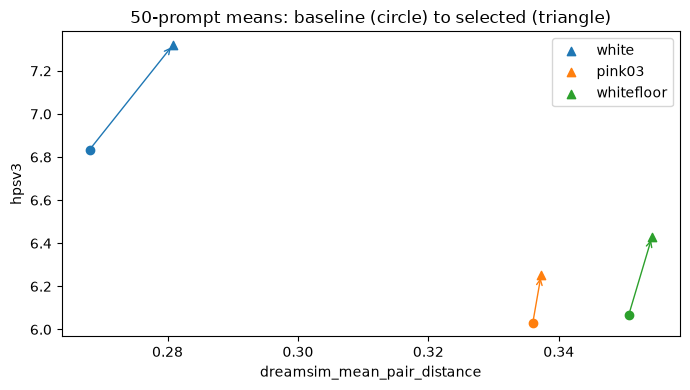

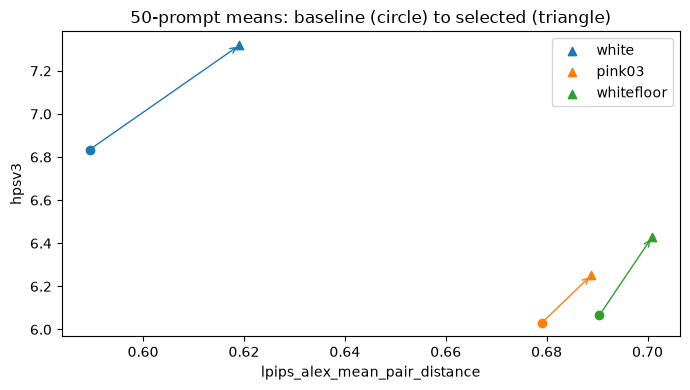

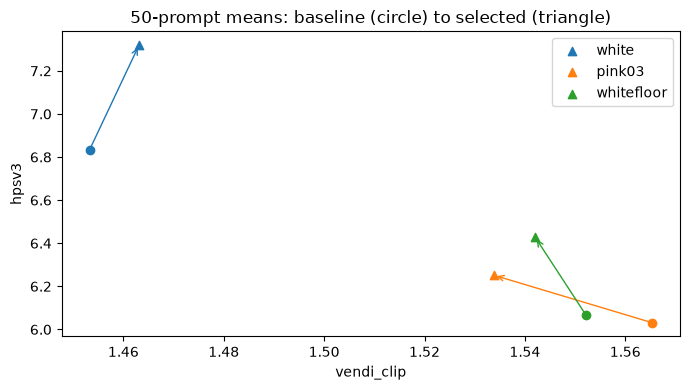

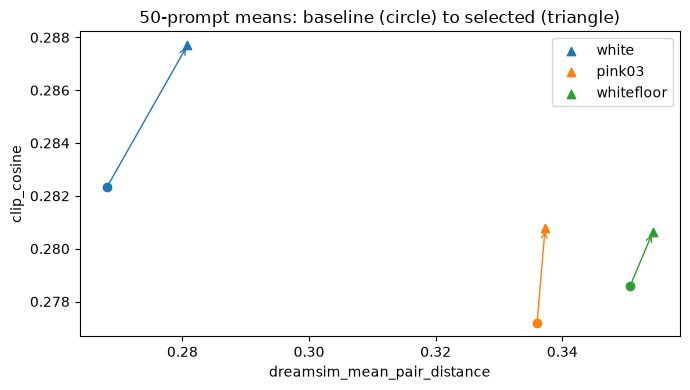

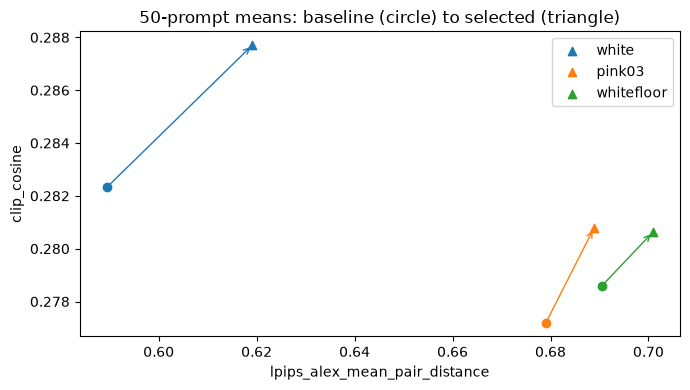

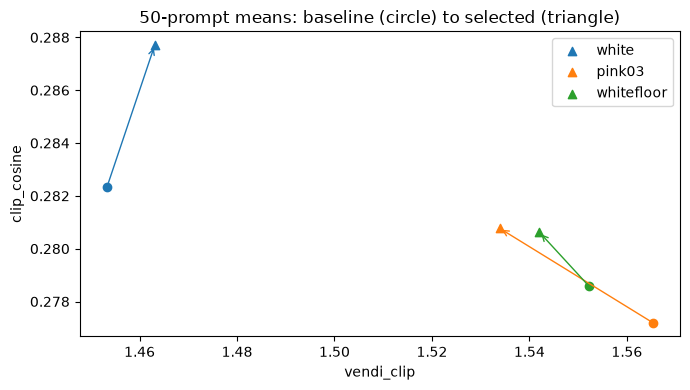

Optimization-only cost, edit size and HPSv2 changes; means across prompts.


,baseline_hpsv2,selected_hpsv2,delta_hpsv2,selected_max_relative_edit,optimization_seconds,peak_cuda_allocated_gb
init_name,,,,,,
pink03,0.290094,0.293449,0.003355,0.019954,82.495515,14.955647
white,0.291854,0.296734,0.004879,0.022932,82.526541,14.955674
whitefloor,0.289946,0.294099,0.004152,0.022187,82.520305,14.955647


In [11]:
STATUS = pd.read_csv(metrics_dir/'metric_status.csv')
display(STATUS)
GROUP = pd.read_csv(metrics_dir/'per_group.csv')
lookup = {r['condition']:r for r in GENERATION_MANIFEST['records']}
for column in ['prompt_id','category','init_name','local_condition']:
    GROUP[column] = GROUP.condition.map(lambda key:lookup[key][column])
GROUP.to_csv(metrics_dir/'per_prompt_scores.csv',index=False)
prompt_ids = [r['prompt_id'] for r in GENERATION_MANIFEST['prompts']]
names = ['white','pink03','whitefloor']
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 20261023
# Same resampled prompt indices across methods and before/after.
boot = np.random.default_rng(BOOTSTRAP_SEED).integers(0,len(prompt_ids),(BOOTSTRAP_REPLICATES,len(prompt_ids)))
def mean_ci(values):
    values = np.asarray(values,dtype=float)
    lo,hi=np.quantile(values[boot].mean(axis=1),[.025,.975])
    return float(values.mean()),float(lo),float(hi)

summary, comparisons, detail, skipped = [], [], [], []
expected_columns = pd.MultiIndex.from_product([names,['baseline','edit_1']],names=['init_name','local_condition'])
valid_scores={}
for metric, part in GROUP.groupby('metric',sort=False):
    table = part.pivot(index='prompt_id',columns=['init_name','local_condition'],values='score')
    table = table.reindex(index=prompt_ids,columns=expected_columns)
    if not np.isfinite(table.to_numpy()).all():
        skipped.append(dict(metric=metric,missing_or_nonfinite=int((~np.isfinite(table.to_numpy())).sum())))
        continue
    valid_scores[metric]=table
    for name in names:
        before=table[(name,'baseline')].to_numpy();after=table[(name,'edit_1')].to_numpy();delta=after-before
        bm,bl,bh=mean_ci(before);am,al,ah=mean_ci(after);dm,dl,dh=mean_ci(delta)
        summary.append(dict(metric=metric,init_name=name,n_prompts=len(prompt_ids),baseline=bm,
            baseline_ci_low=bl,baseline_ci_high=bh,optimized=am,optimized_ci_low=al,optimized_ci_high=ah,
            delta=dm,delta_ci_low=dl,delta_ci_high=dh,
            relative_pct=100*dm/bm if bm>1e-12 else np.nan,
            fraction_increased=float((delta>0).mean())))
        for pid,b,a,d in zip(prompt_ids,before,after,delta):
            detail.append(dict(prompt_id=pid,init_name=name,metric=metric,baseline=b,optimized=a,delta=d))
    for other in ['white','pink03']:
        for comparison in ['optimized','gain']:
            a=table[('whitefloor','edit_1')].to_numpy();b=table[(other,'edit_1')].to_numpy()
            if comparison=='gain':
                a=a-table[('whitefloor','baseline')].to_numpy();b=b-table[(other,'baseline')].to_numpy()
            avg,lo,hi=mean_ci(a-b)
            comparisons.append(dict(metric=metric,comparison=comparison,contrast='whitefloor - '+other,
                n_prompts=len(prompt_ids),difference=avg,ci_low=lo,ci_high=hi))
SUMMARY=pd.DataFrame(summary); CONTRASTS=pd.DataFrame(comparisons)
SUMMARY.to_csv(metrics_dir/'summary_prompt_equal_weight.csv',index=False)
CONTRASTS.to_csv(metrics_dir/'paired_initialization_comparisons.csv',index=False)
pd.DataFrame(detail).to_csv(metrics_dir/'per_prompt_delta.csv',index=False)
pd.DataFrame(skipped,columns=['metric','missing_or_nonfinite']).to_csv(metrics_dir/'excluded_incomplete_metrics.csv',index=False)
if skipped:print('Excluded incomplete metrics:',skipped)
key_metrics=['hpsv3','clip_cosine','maniqa','dreamsim_mean_pair_distance','lpips_alex_mean_pair_distance','vendi_clip']
if len(SUMMARY):
    print('Equal prompt weights; paired prompt-bootstrap 95% CIs for changes.')
    display(SUMMARY[SUMMARY.metric.isin(key_metrics)][['metric','init_name','baseline','optimized','delta','delta_ci_low','delta_ci_high','relative_pct','fraction_increased']])
    print('Whitefloor minus another initialization: final-score and improvement differences.')
    display(CONTRASTS[CONTRASTS.metric.isin(key_metrics)])
    categories=GROUP[GROUP.metric.isin(valid_scores)].groupby(['category','init_name','local_condition','metric']).score.agg(['mean','count'])
    categories.to_csv(metrics_dir/'summary_by_category.csv')
    for quality in ['hpsv3','clip_cosine']:
        for diversity in ['dreamsim_mean_pair_distance','lpips_alex_mean_pair_distance','vendi_clip']:
            if quality not in valid_scores or diversity not in valid_scores:continue
            fig,ax=plt.subplots(figsize=(7,4))
            for name,color in zip(names,['tab:blue','tab:orange','tab:green']):
                q=valid_scores[quality];d=valid_scores[diversity]
                x0=d[(name,'baseline')].mean();y0=q[(name,'baseline')].mean()
                x1=d[(name,'edit_1')].mean();y1=q[(name,'edit_1')].mean()
                ax.scatter(x0,y0,color=color,marker='o');ax.scatter(x1,y1,color=color,marker='^',label=name)
                ax.annotate('',xy=(x1,y1),xytext=(x0,y0),arrowprops=dict(arrowstyle='->',color=color))
            ax.set(xlabel=diversity,ylabel=quality,title='50-prompt means: baseline (circle) to selected (triangle)');ax.legend()
            fig.tight_layout();fig.savefig(metrics_dir/f'mean_{quality}_vs_{diversity}.png',dpi=140);plt.show();plt.close(fig)
opt=pd.read_csv(RUN_DIR/'optimization_summary.csv')
print('Optimization-only cost, edit size and HPSv2 changes; means across prompts.')
display(opt.groupby('init_name')[['baseline_hpsv2','selected_hpsv2','delta_hpsv2','selected_max_relative_edit','optimization_seconds','peak_cuda_allocated_gb']].mean())
opt.groupby('init_name').mean(numeric_only=True).to_csv(metrics_dir/'optimization_summary_means.csv')
print('Generation directory:',RUN_DIR)
print('One four-image group per prompt. CIs reflect prompt variation, not repeated-seed uncertainty.')

print('Evaluation directory:', metrics_dir)
print('optimization_seconds is NOT end-to-end generation cost; do not equate it with a differently timed DivGen run.')


## 14. Reading the results

Interpret diversity alongside quality and text alignment. MANIQA measures perceptual quality, not sharpness alone. With one image group per prompt, the confidence intervals reflect prompt variation rather than repeated-seed uncertainty. GenEval supplies the prompts; detector-based GenEval accuracy is not computed here.

`optimization_seconds` and peak CUDA allocation cover the optimisation stage. Per-group `timings.json` files contain additional stage timings and wall time, including setup, validation, baseline output, and display. Use matching measurement boundaries when comparing costs across methods.
